# Combining H_001, H_002, H003 with  H_007 and H_008

This is the uninformative priors repeated for 5 seeds and for all experimental plans.

In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import diffrax as dfx

# jax.config.update("jax_disable_jit",True)
jax.local_device_count()

import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import xarray
import ICIW_Plots
import tqdm

plt.style.use("ICIWstyle")
plt.rcParams.update(
    {
        "figure.dpi": 600,
        "font.size": 7,
        # "axes.linewidth": 0.8,
        # "axes.spines.top": False,
        # "axes.spines.right": False,
        # "axes.grid": False,
        # "legend.frameon": False,
    }
)

In [2]:
%config InlineBackend.print_figure_kwargs = {'bbox_inches':None}


In [3]:
from HSA_Cam_B_039_numpyro import kl_divergence_between_models
from HSA_Mo_B_011_numpyro import (
    kinetics_model,
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    validate_against_holdout,
    sample_prior,
    TRUE_PARAMS,
)

In [4]:
ov = [
    {
        "ID": "H_001",
        "run_name": "verdant-stack",
        "dir": Path("data/verdant-stack"),
        "DOE": "Koschany DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "paramEKLDS": {},
        "paramEKLDS_to_prior": {},
    },
    {
        "ID": "H_002",
        "run_name": "maroon-downtown",
        "dir": Path("data/maroon-downtown"),
        "DOE": "paramEKLD DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "paramEKLDS": {},
        "paramEKLDS_to_prior": {},
    },
    {
        "ID": "H_003",
        "run_name": "persistent-hardcover",
        "dir": Path("data/persistent-hardcover"),
        "DOE": "predEKLD DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "paramEKLDS": {},
        "paramEKLDS_to_prior": {},
    },
    {
        "ID": "H_007",
        "run_name": "isolated-question",
        "dir": Path("data/isolated-question"),
        "DOE": "LHS32 DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "paramEKLDS": {},
        "paramEKLDS_to_prior": {},
    },
    {
        "ID": "H_008",
        "run_name": "strong-cartwheel",
        "dir": Path("data/strong-cartwheel"),
        "DOE": "LHS64 DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "paramEKLDS": {},
        "paramEKLDS_to_prior": {},
    },
]

In [5]:
def load_files(ov_dict, seed):
    seed_dir = ov_dict["dir"] / f"seed{seed:03d}"
    # print(seed_dir)
    #sum_file = seed_dir / f"experiment_summary.json" #doesnt work for symlink
    sum_file = list(seed_dir.glob(f"experiment_summary*.json"))[0]
    trace_files = sorted(seed_dir.glob(f"trace_*.nc"))
    # print(sum_file)
    test_data = xarray.open_dataset(ov_dict["holdout_data"])
    idatas = []
    valdatas = []
    paramEKLDS = []
    paramEKLDS_to_prior = []
    for i, trace_file in enumerate(tqdm.tqdm(trace_files)):
        idata = az.from_netcdf(trace_file)
        if i == 0:
            idata.update(xarray.DataTree.from_dict({"prior": sample_prior(4000).prior}))
        else:
            idata.update(
                xarray.DataTree.from_dict({"prior": idatas[i - 1]["posterior"].dataset})
            )
        idatas.append(idata)
        valdata = validate_against_holdout(
            idata,
            test_data,
            num_samples=5000,
        )
        paramEKLD = kl_divergence_between_models(
            idata_new=idata,
            idata_old=idata,
            key_new="posterior",
            key_old="prior",
            var_names=[
                "k0",
                "Ea_k",
                "A_oh",
                "dH_oh",
                "A_h2",
                "dH_h2",
                "A_mix",
                "dH_mix",
                "sigma_r",
            ],
        ).sum()
        paramEKLD_to_prior = kl_divergence_between_models(
            idata_new=idata,
            idata_old=idatas[0],
            key_new="posterior",
            key_old="prior",
            var_names=[
                "k0",
                "Ea_k",
                "A_oh",
                "dH_oh",
                "A_h2",
                "dH_h2",
                "A_mix",
                "dH_mix",
                "sigma_r",
            ],
        ).sum()
        paramEKLDS.append(paramEKLD)
        paramEKLDS_to_prior.append(paramEKLD_to_prior)
        valdatas.append(valdata)
    ov_dict["idatas"][seed] = idatas
    ov_dict["valdatas"][seed] = valdatas
    ov_dict["paramEKLDS"][seed] = paramEKLDS
    ov_dict["paramEKLDS_to_prior"][seed] = paramEKLDS_to_prior
    with open(sum_file, "r") as f:
        exp_summary = json.load(f)
    ov_dict["proposals"][seed] = np.array(exp_summary["trials"][-1]["observed"]["x"])
    ov_dict["r_obs"][seed] = np.array(exp_summary["trials"][-1]["observed"]["y"])

def get_seeds(ov_dict):
    master_file = ov_dict["dir"] / f"multi_seed_summary.json"
    with open(master_file, "r") as f:
        seed_summary = json.load(f)
    seeds = seed_summary["seeds_used"]
    ov_dict["seeds"] = seeds
    return seeds

In [6]:
for ov_dict in ov:
    seeds=get_seeds(ov_dict)
    print(seeds)
    for seed in seeds:
            load_files(ov_dict, seed)
    # load_files(ov_dict)
    # print(ov_dict["r_obs"])

[42, 43, 44, 45, 46]


100%|██████████| 64/64 [00:33<00:00,  1.89it/s]


[43, 44, 45, 46, 47]


100%|██████████| 32/32 [00:17<00:00,  1.83it/s]


[43, 44, 45, 46, 47]


100%|██████████| 32/32 [00:17<00:00,  1.84it/s]


[42, 43, 44, 45, 46]


100%|██████████| 32/32 [00:17<00:00,  1.83it/s]


[42, 43, 44, 45, 46]


100%|██████████| 64/64 [00:34<00:00,  1.86it/s]


In [7]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[var_name].values
    pred = postdata.posterior_predictive[var_name].values
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=2)).squeeze()
    return rmse_vals


def calculate_RMSEs(ov_dict, seed):
    ov_dict["RMSEs"][seed] = None
    for valdata in ov_dict["valdatas"][seed]:
        rmse_da = bRMSE(valdata, "r_pred")
        if ov_dict["RMSEs"][seed] is None:
            ov_dict["RMSEs"][seed] = [rmse_da]
        else:
            ov_dict["RMSEs"][seed].append(rmse_da)
    ov_dict["RMSEs"][seed] = np.array(ov_dict["RMSEs"][seed])

In [8]:
for ov_dict in ov:
    for seed in ov_dict["seeds"]:
        calculate_RMSEs(ov_dict, seed)

In [9]:
ov[0]["RMSEs"][43][-1].shape

(5000,)

In [10]:
for ov_dict in ov:
    print(ov_dict["run_name"])
    for seed in ov_dict["seeds"]:
        print(f"Seed {seed}: RMSE mean = {ov_dict['RMSEs'][seed][-1].mean()}, 95% HDI = {az.hdi(ov_dict['RMSEs'][seed][-1], prob=0.95)}")


verdant-stack
Seed 42: RMSE mean = 3.0136106454552482e-06, 95% HDI = [8.70912277e-07 5.37342184e-06]
Seed 43: RMSE mean = 5.7226829245057995e-06, 95% HDI = [1.98149186e-06 9.85777441e-06]
Seed 44: RMSE mean = 3.4310311933599206e-06, 95% HDI = [6.98465667e-07 6.70079917e-06]
Seed 45: RMSE mean = 5.0457277190141845e-06, 95% HDI = [1.67246155e-06 8.85428185e-06]
Seed 46: RMSE mean = 3.6564612388056082e-06, 95% HDI = [9.05533685e-07 7.08711433e-06]
maroon-downtown
Seed 43: RMSE mean = 2.4953972919173658e-06, 95% HDI = [4.44717941e-07 4.99725428e-06]
Seed 44: RMSE mean = 3.2131780775082663e-06, 95% HDI = [5.92368623e-07 6.54933774e-06]
Seed 45: RMSE mean = 3.4183068259062033e-06, 95% HDI = [7.00602692e-07 6.50142834e-06]
Seed 46: RMSE mean = 3.522027854721752e-06, 95% HDI = [7.27785109e-07 7.45059350e-06]
Seed 47: RMSE mean = 6.64601657183031e-06, 95% HDI = [1.17283017e-06 1.26495570e-05]
persistent-hardcover
Seed 43: RMSE mean = 2.1218927445541572e-06, 95% HDI = [5.63607799e-07 4.25127398e

### Predictive accuracy

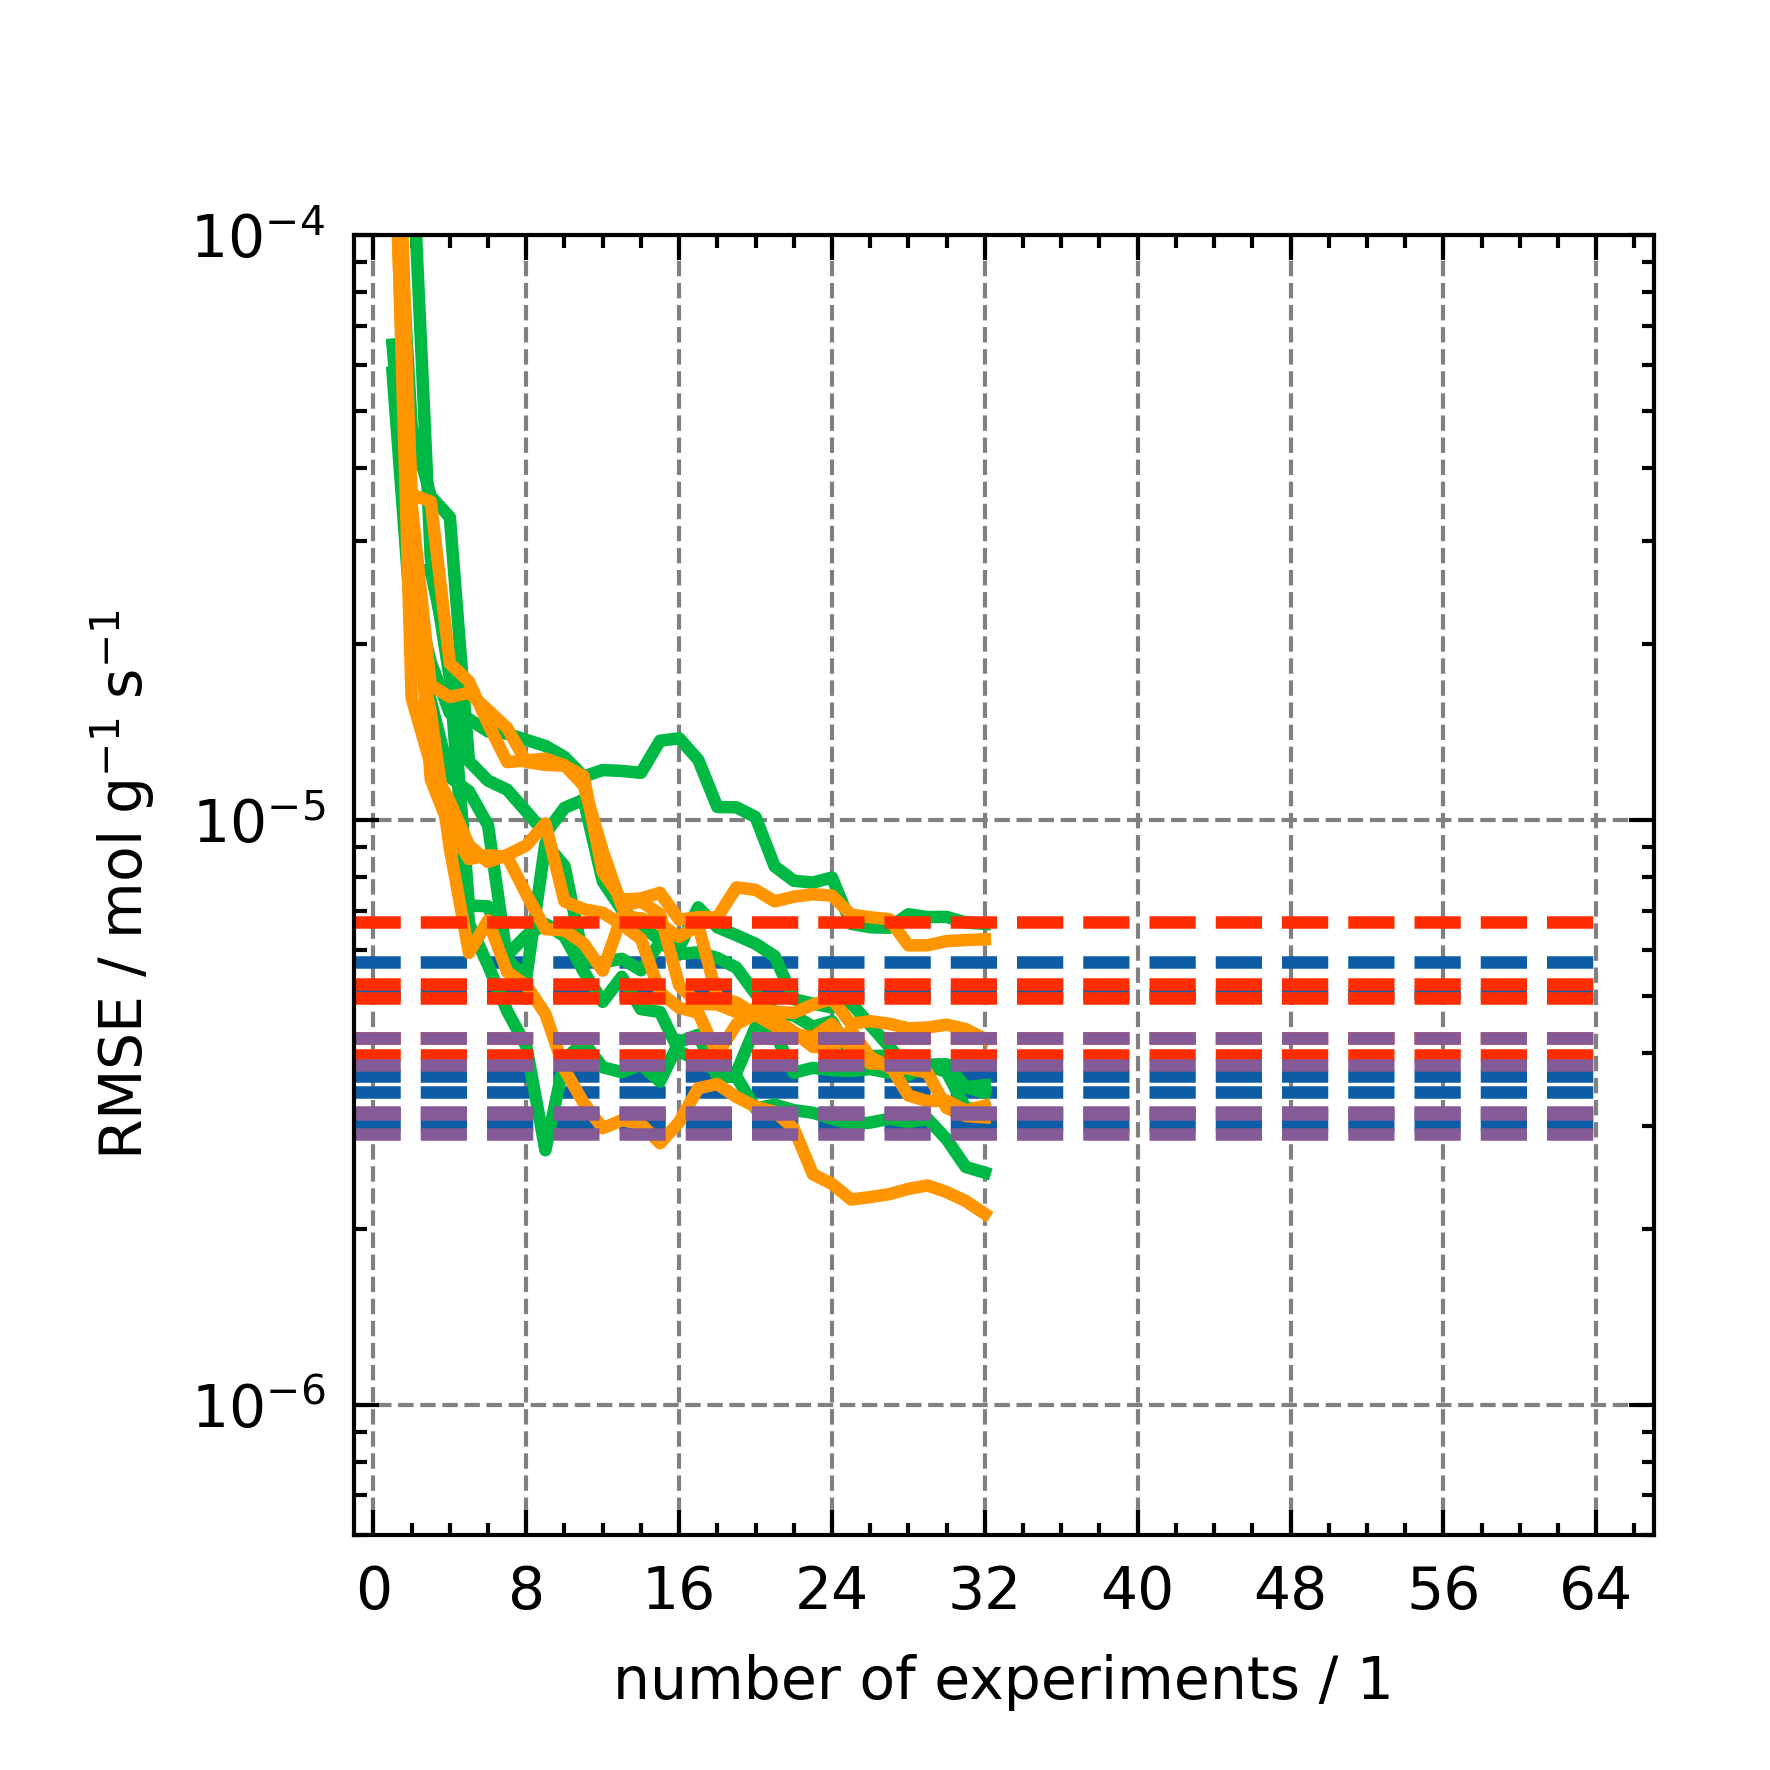

In [11]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, ov_dict in enumerate(ov):
    for seed in ov_dict["seeds"]:

        if ov_dict["DOE"] in ["Koschany DOE", "LHS32 DOE", "LHS64 DOE"]:
            ax.hlines(
                np.mean(ov_dict["RMSEs"][seed], axis=1)[-1],
                xmin=-1,
                xmax=64,
                label=ov_dict["DOE"],
                ls="--",
                color=colors[i],
            )
            # HDI = az.hdi(ov_dict["RMSEs"][seed][-1], prob=0.95)
            # ax.fill_between(
            #     np.arange(-1, len(ov_dict["RMSEs"][seed]) + 1),
            #     HDI[0],
            #     HDI[1],
            #     alpha=0.2,
            #     # ls="--",
            #     facecolor=colors[i],
            #     # edgecolor="gray",
            # )
            continue
        ax.plot(
            np.arange(1, len(ov_dict["RMSEs"][seed]) + 1),
            np.mean(ov_dict["RMSEs"][seed], axis=1),
            # "o--",
            # ms=4,
            # lw=1,
            label=ov_dict["DOE"],
            color=colors[i],
        )
        # HDI = az.hdi(ov_dict["RMSEs"][seed].T, prob=0.95)
        # print(HDI.shape)
        # ax.fill_between(
        #     np.arange(1, len(ov_dict["RMSEs"][seed]) + 1),
        #     HDI[:, 0],
        #     HDI[:, 1],
        #     alpha=0.2,
        #     # ls="--",
        #     facecolor=colors[i],
        #     # edgecolor="gray",
        # )
    # ax.legend(frameon=True)

# plt.savefig("figures/KinFit_RMSE.png")
# plt.savefig("figures/KinFit_RMSE.pdf")
# plt.savefig("figures/KinFit_RMSE.svg")

Koschany DOE
(64, 2)
LHS32 DOE
(32, 2)
LHS64 DOE
(64, 2)


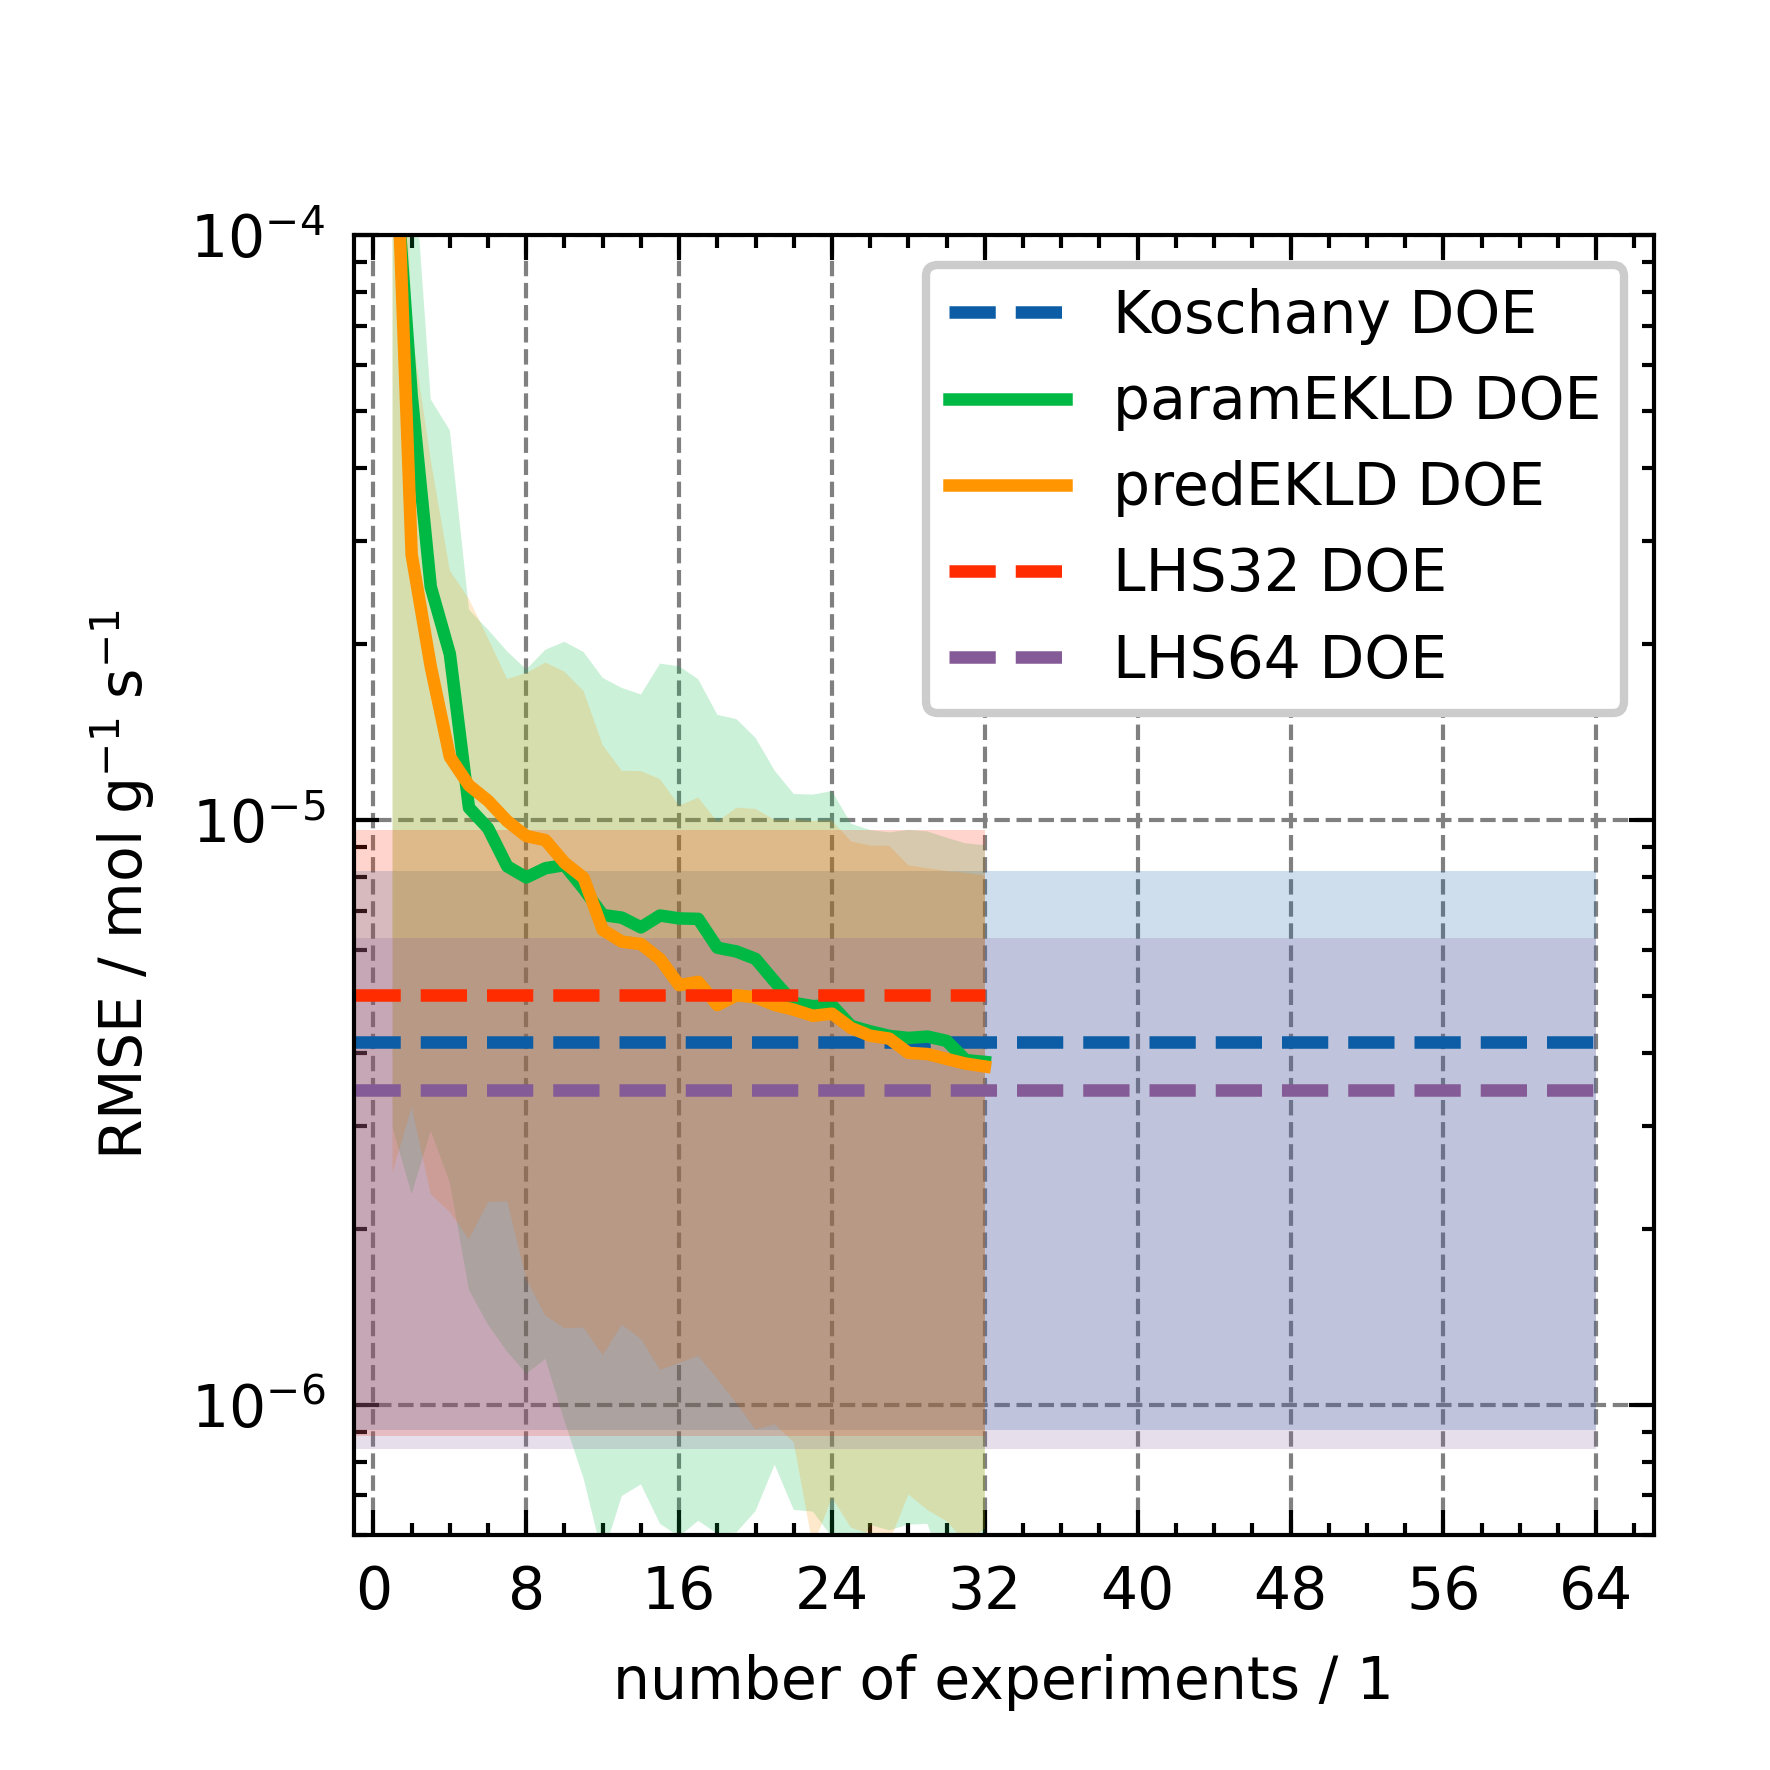

In [13]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, ov_dict in enumerate(ov):
    RMSEs = np.concatenate([ov_dict["RMSEs"][seed] for seed in ov_dict["seeds"]], axis=-1)
    if ov_dict["DOE"] in ["Koschany DOE", "LHS32 DOE", "LHS64 DOE"]:
        print(ov_dict["DOE"])
        xmax = len(ov_dict["RMSEs"][seed])
        ax.hlines(
            np.mean(RMSEs, axis=1)[-1],
            xmin=-1,
            xmax=xmax,
            label=ov_dict["DOE"],
            ls="--",
            color=colors[i],
        )
        HDI = az.hdi(RMSEs, prob=0.95, dim=0,)
        print(HDI.shape)
        ax.fill_between(
            np.arange(-1, RMSEs.shape[0] + 1),
            HDI[-1,0],
            HDI[-1,1],
            alpha=0.2,
            # ls="--",
            facecolor=colors[i],
            # edgecolor="gray",
        )
        continue
    ax.plot(
        np.arange(1, RMSEs.shape[0] + 1),
        np.mean(RMSEs, axis=1),
        # "o--",
        # ms=4,
        # lw=1,
        label=ov_dict["DOE"],
        color=colors[i],
    )
    HDI = az.hdi(RMSEs, prob=0.95)
    ax.fill_between(
        np.arange(1, RMSEs.shape[0] + 1),
        HDI[:, 0],
        HDI[:, 1],
        alpha=0.2,
        # ls="--",
        facecolor=colors[i],
        # edgecolor="gray",
    )
ax.legend(frameon=True)

plt.savefig("figures/rev/KinFit_RMSE.png")
plt.savefig("figures/rev/KinFit_RMSE.pdf")
plt.savefig("figures/rev/KinFit_RMSE.svg")

(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)


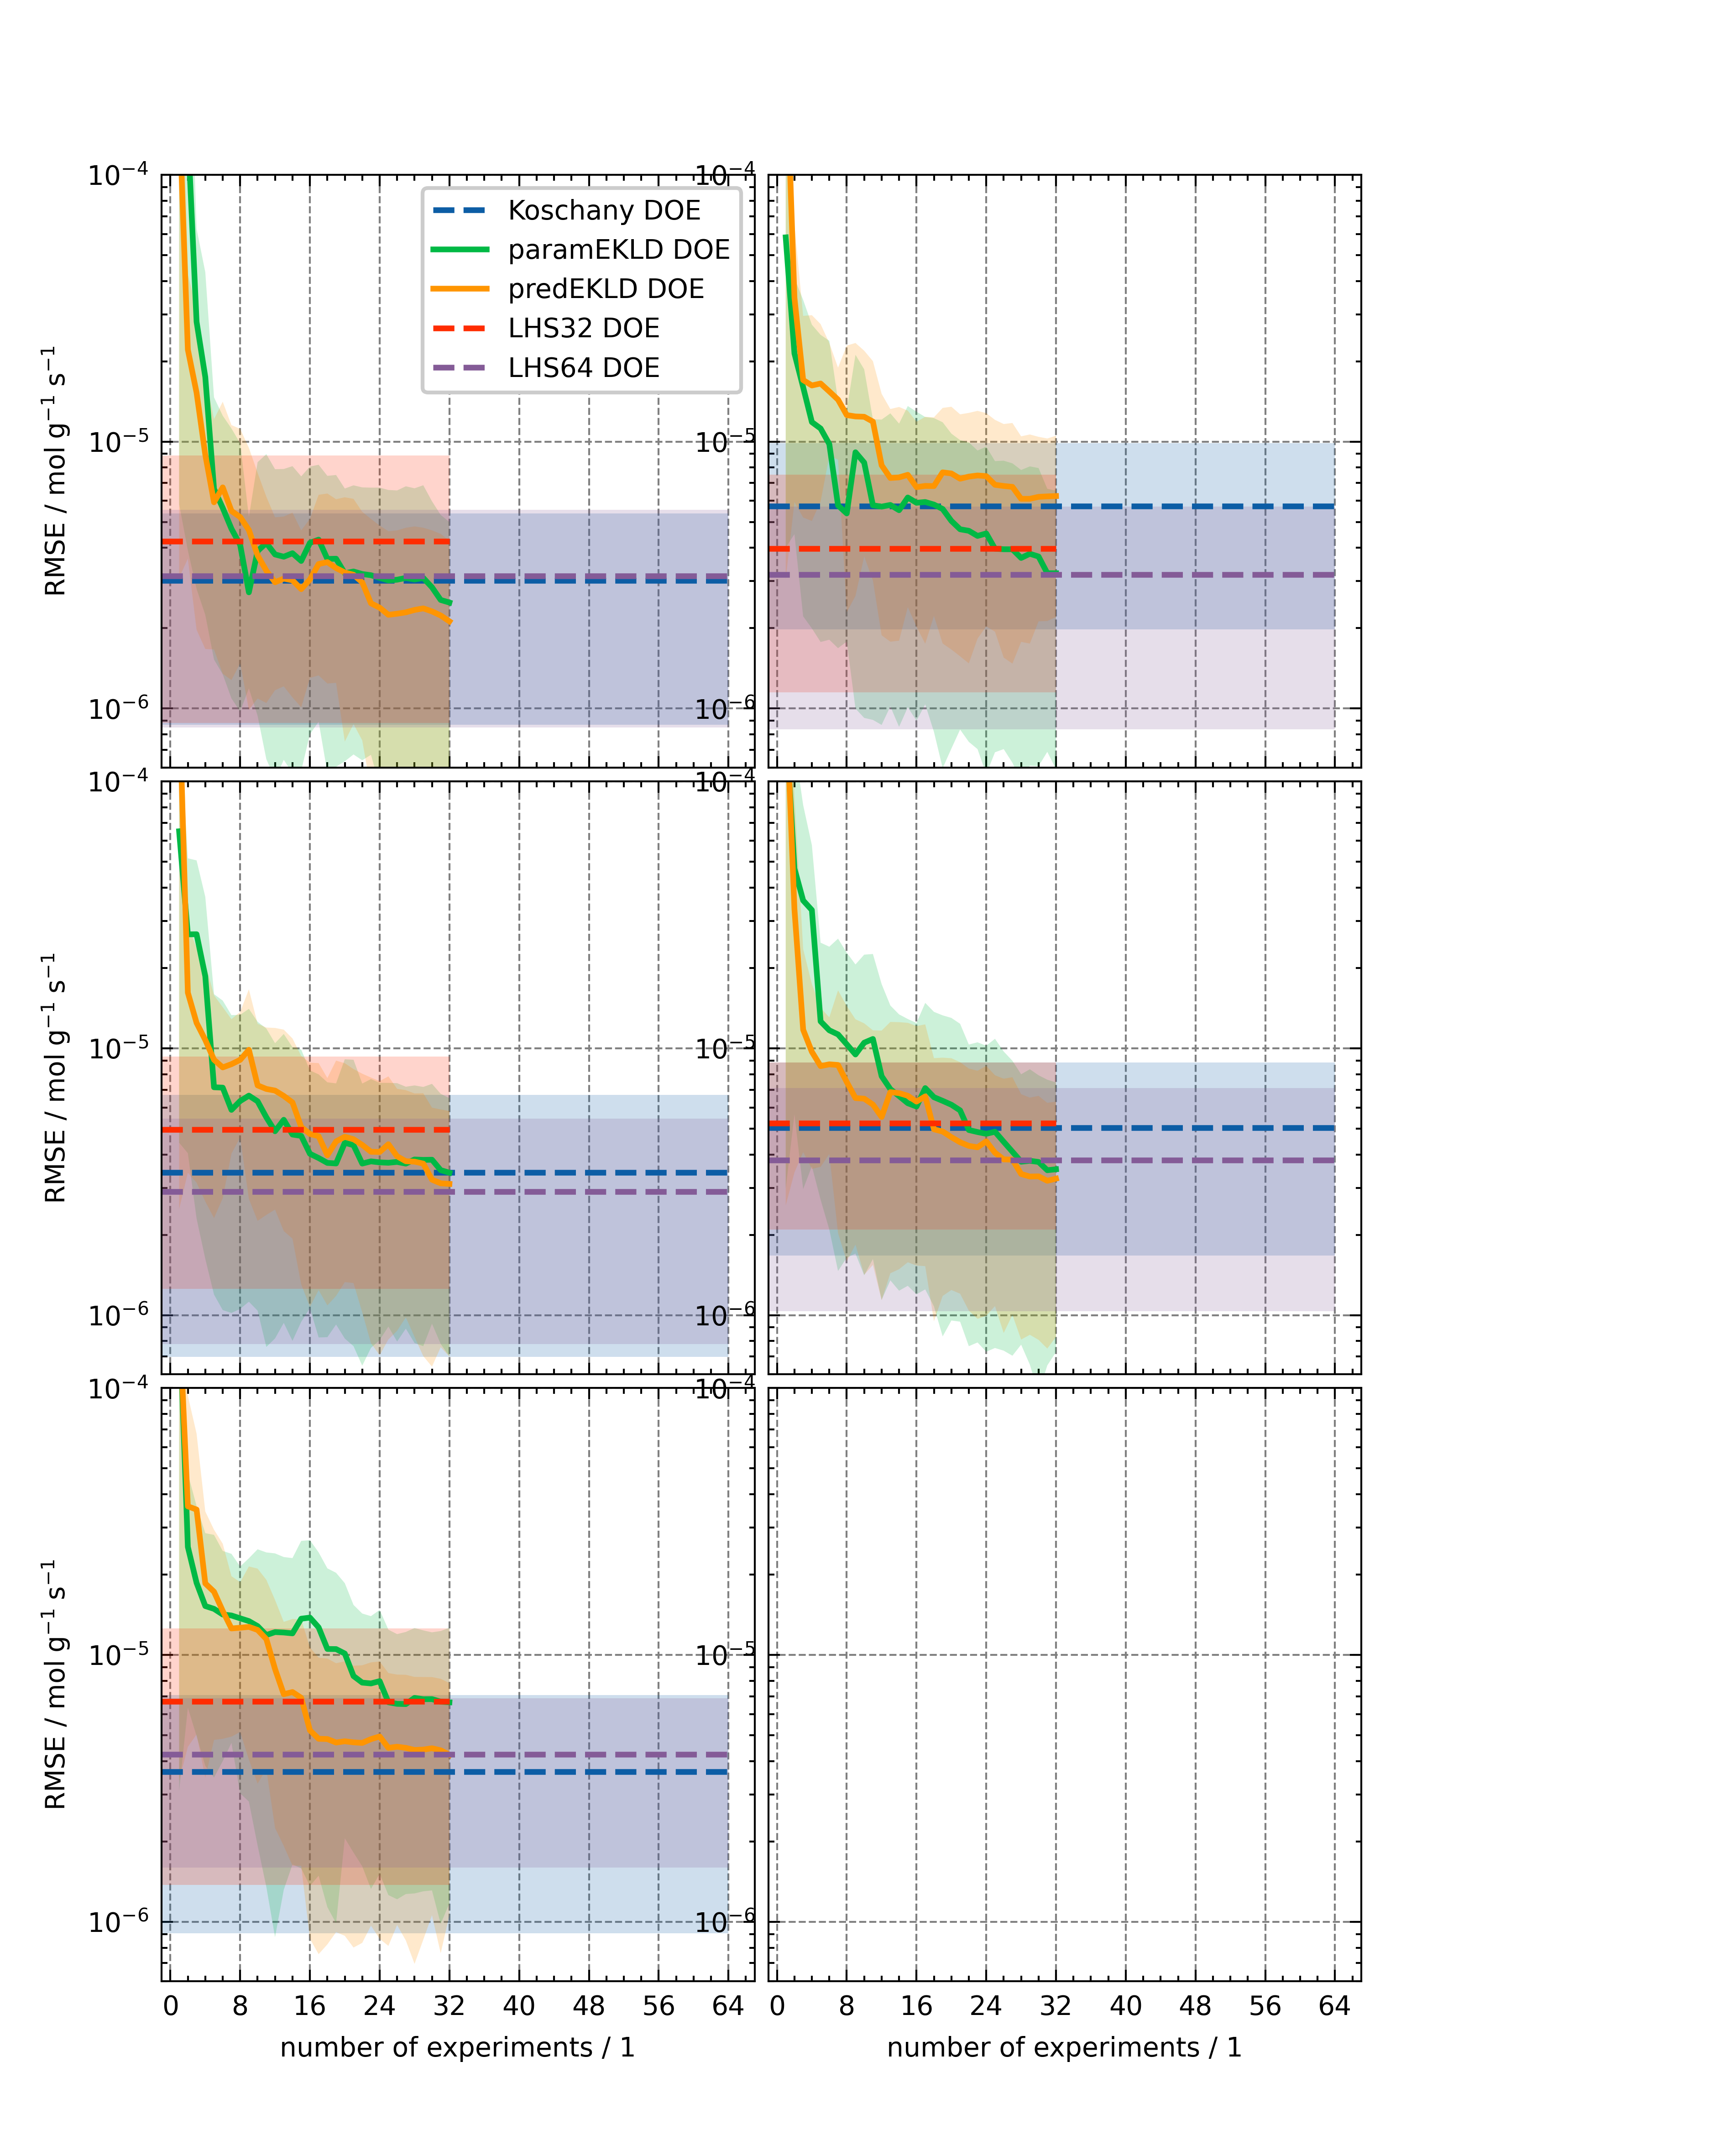

In [14]:
fig = ICIW_Plots.figure(layout="double_column", height=20*ICIW_Plots.cm2inch)
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(3,2),
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    sharex=True,
    sharey=True,
    ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)
axs = axs.flatten()

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, ov_dict in enumerate(ov):
    for seed_idx, seed in enumerate(ov_dict["seeds"]):

        if ov_dict["DOE"] in ["Koschany DOE", "LHS32 DOE", "LHS64 DOE"]:
            xmax = len(ov_dict["RMSEs"][seed])
            axs[seed_idx].hlines(
                np.mean(ov_dict["RMSEs"][seed], axis=1)[-1],
                xmin=-1,
                xmax=xmax,
                label=ov_dict["DOE"],
                ls="--",
                color=colors[i],
            )
            HDI = az.hdi(ov_dict["RMSEs"][seed][-1], prob=0.95)
            axs[seed_idx].fill_between(
                np.arange(-1, len(ov_dict["RMSEs"][seed]) + 1),
                HDI[0],
                HDI[1],
                alpha=0.2,
                # ls="--",
                facecolor=colors[i],
                # edgecolor="gray",
            )
            continue
        axs[seed_idx].plot(
            np.arange(1, len(ov_dict["RMSEs"][seed]) + 1),
            np.mean(ov_dict["RMSEs"][seed], axis=1),
            # "o--",
            # ms=4,
            # lw=1,
            label=ov_dict["DOE"],
            color=colors[i],
        )
        HDI = az.hdi(ov_dict["RMSEs"][seed], prob=0.95)
        print(HDI.shape)
        axs[seed_idx].fill_between(
            np.arange(1, len(ov_dict["RMSEs"][seed]) + 1),
            HDI[:, 0],
            HDI[:, 1],
            alpha=0.2,
            # ls="--",
            facecolor=colors[i],
            # edgecolor="gray",
        )
    axs[0].legend(frameon=True)

plt.savefig("figures/rev/KinFit_RMSE_by_seed.png")
plt.savefig("figures/rev/KinFit_RMSE_by_seed.pdf")
plt.savefig("figures/rev/KinFit_RMSE_by_seed.svg")

### Information Gain

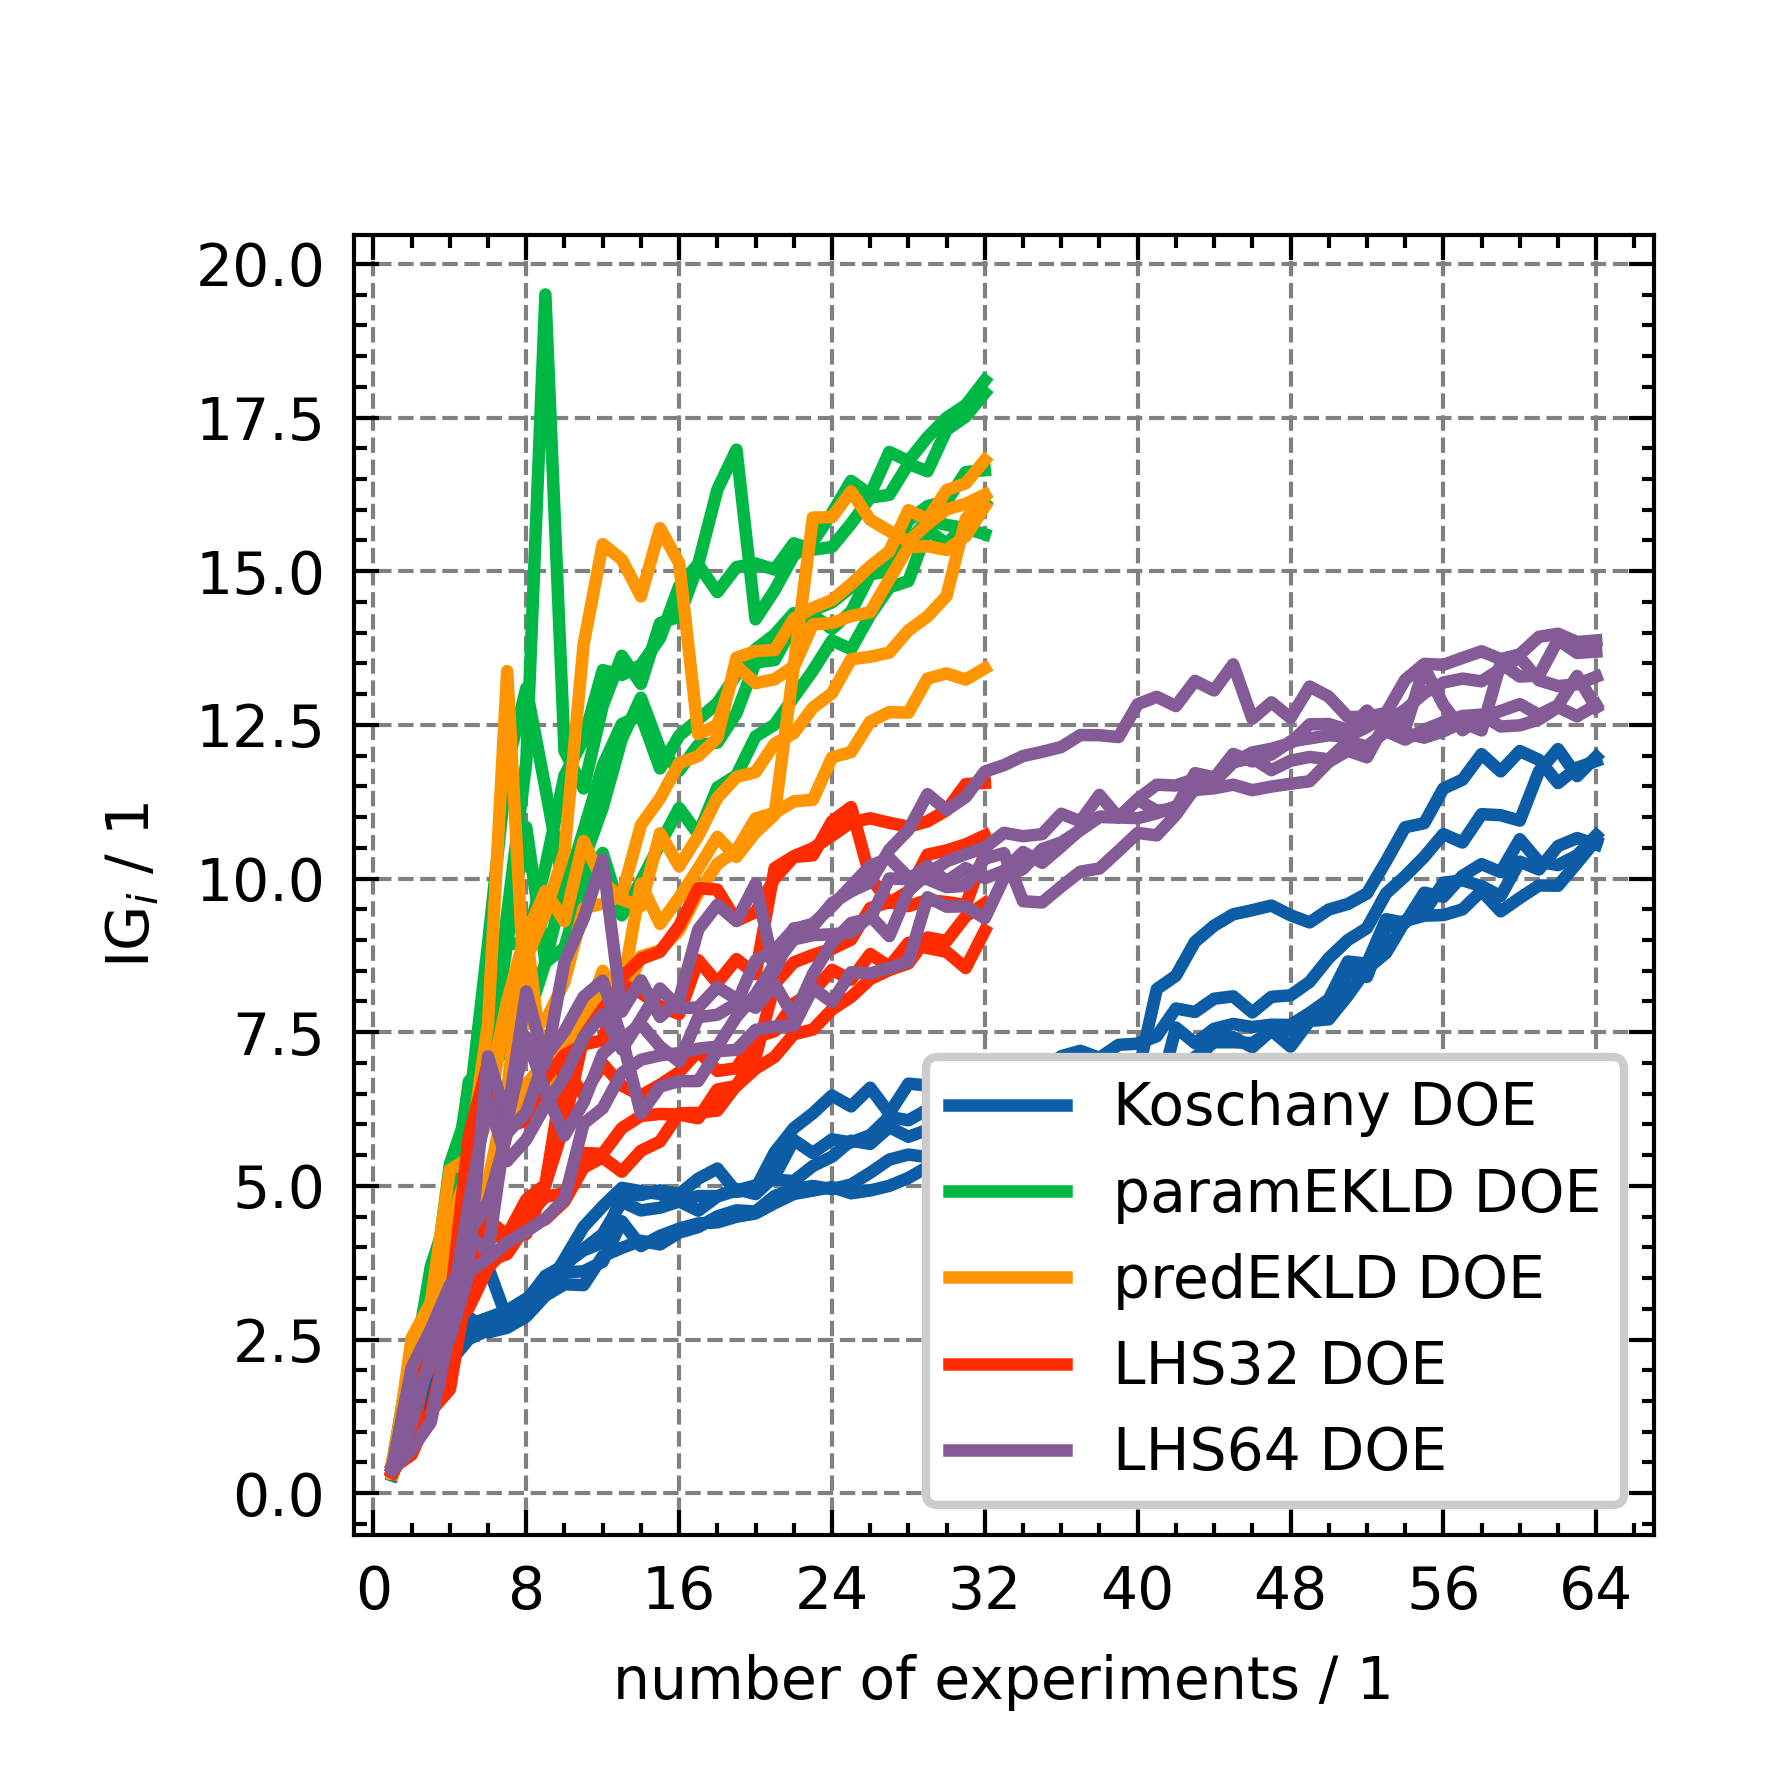

In [15]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"$\mathrm{IG}_i$ / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)
for i, ov_dict in enumerate(ov):
    for seed_idx, seed in enumerate(ov_dict["seeds"]):
        label = ov_dict["DOE"] if seed_idx == 0 else "_nolegend_"

        ax.plot(
            np.arange(len(ov_dict["paramEKLDS_to_prior"][seed])) + 1,
            ov_dict["paramEKLDS_to_prior"][seed],
            label=label,
            color=colors[i],
        )
    ax.legend()

plt.savefig("figures/rev/KinFit_IG_by_seed.png")
plt.savefig("figures/rev/KinFit_IG_by_seed.pdf")
plt.savefig("figures/rev/KinFit_IG_by_seed.svg")

(64, 5)
(32, 5)
(32, 5)
(32, 5)
(64, 5)


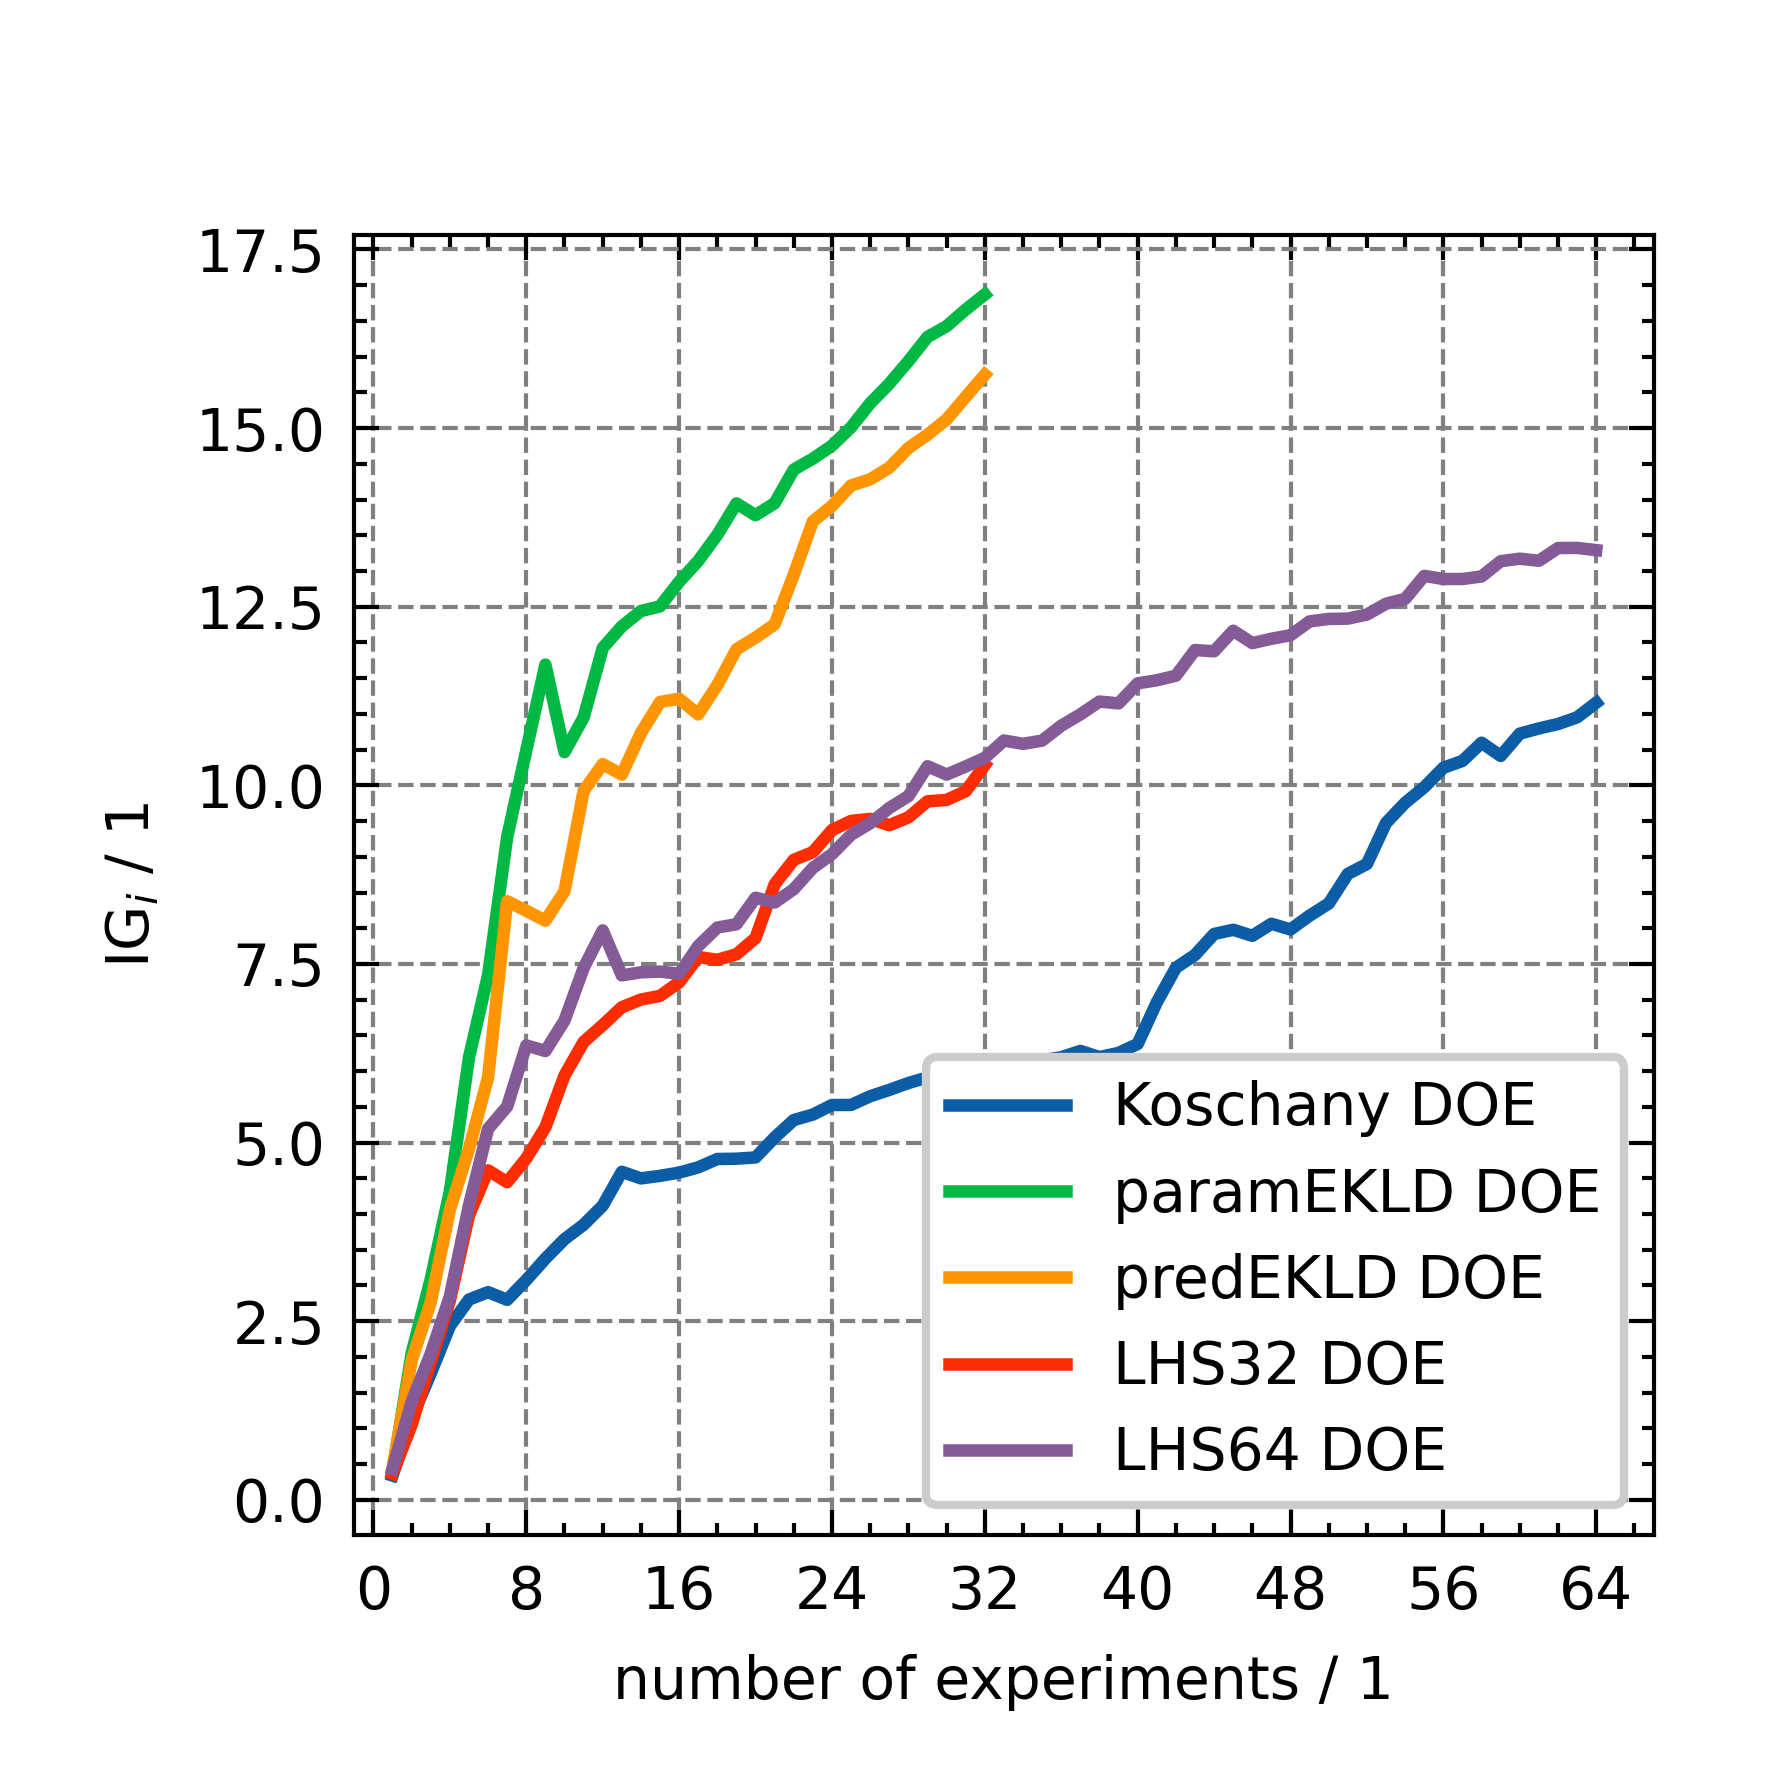

In [16]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"$\mathrm{IG}_i$ / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)
for i, ov_dict in enumerate(ov):
    IGs = np.stack([ov_dict["paramEKLDS_to_prior"][seed] for seed in ov_dict["seeds"]], axis=-1)
    print(IGs.shape)
    ax.plot(
        np.arange(IGs.shape[0]) + 1,
        IGs.mean(axis=1),
        label=ov_dict["DOE"],
        color=colors[i],
        
    )
    ax.legend()

plt.savefig("figures/rev/KinFit_IG.png")
plt.savefig("figures/rev/KinFit_IG.pdf")
plt.savefig("figures/rev/KinFit_IG.svg")

### Parameter identified

In [17]:
def collect_param_samples_by_seed_and_step(ov_dict, key):
    """Return posterior samples with explicit seed and step dimensions."""
    per_seed = []
    for seed in ov_dict["seeds"]:
        per_step = []
        for step, idata in enumerate(ov_dict["idatas"][seed]):
            samples = idata.posterior[key].stack(sample=("chain", "draw")).values
            per_step.append(
                xarray.DataArray(
                    samples,
                    dims=("sample",),
                    coords={"sample": np.arange(samples.size)},
                ).expand_dims(step=[step])
            )
        per_seed.append(xarray.concat(per_step, dim="step").expand_dims(seed=[seed]))
    return xarray.concat(per_seed, dim="seed")


In [18]:
display(temp_data:=collect_param_samples_by_seed_and_step(ov[0], "k0"))
az.mean(temp_data, dim=("sample", "seed")).shape

<xarray.DataArray (seed: 5, step: 64, sample: 32000)> Size: 41MB
array([[[1.47777580e-04, 1.15555384e-04, 2.55162595e-03, ...,
         8.11937280e-05, 1.74344197e-04, 3.77233897e-04],
        [3.11458774e-04, 5.40391193e-04, 4.83620010e-04, ...,
         2.01486808e-04, 2.55836931e-04, 1.04973791e-03],
        [3.77213757e-04, 3.00560525e-04, 4.91660787e-04, ...,
         1.46334482e-04, 4.15423361e-04, 1.20546832e-03],
        ...,
        [3.25863890e-04, 3.53861076e-04, 2.69450800e-04, ...,
         3.45590059e-04, 2.64235365e-04, 3.35406978e-04],
        [3.67768895e-04, 3.92525777e-04, 2.83877598e-04, ...,
         2.90361349e-04, 2.64344999e-04, 2.32910184e-04],
        [3.41968465e-04, 3.59976257e-04, 3.54894903e-04, ...,
         2.81355140e-04, 2.56152096e-04, 3.19235172e-04]],

       [[2.70548742e-04, 2.18780711e-04, 5.76617138e-04, ...,
         1.69195962e-04, 1.67268235e-03, 9.01978347e-04],
        [1.34913623e-03, 1.20976055e-03, 4.88648075e-04, ...,
         1.71493986e-04, 1.91064115e-04, 1.38344965e-03],
        [3.13419674e-04, 1.09933503e-03, 2.32230814e-04, ...,
         3.24064546e-04, 2.99236330e-04, 1.76035985e-03],
...
         2.82216701e-04, 3.56993929e-04, 2.26289194e-04],
        [2.61820765e-04, 2.77133717e-04, 2.66596442e-04, ...,
         2.54481769e-04, 3.14794946e-04, 2.58731219e-04],
        [2.95053993e-04, 3.31143878e-04, 2.82908964e-04, ...,
         2.94260710e-04, 2.65747338e-04, 3.41322855e-04]],

       [[8.51131044e-04, 1.27010723e-03, 1.44056015e-04, ...,
         2.07116274e-04, 9.47147550e-04, 3.07336508e-04],
        [2.82734458e-04, 2.23879251e-04, 2.87596631e-04, ...,
         1.24263309e-03, 1.23173650e-03, 1.23173650e-03],
        [1.46546692e-03, 1.54430512e-03, 3.79062665e-04, ...,
         1.89189828e-04, 1.31232128e-03, 2.96163897e-04],
        ...,
        [3.07548471e-04, 3.48079251e-04, 3.17208236e-04, ...,
         2.86247348e-04, 4.43145051e-04, 2.78733583e-04],
        [3.86046071e-04, 3.87709704e-04, 4.00997786e-04, ...,
         2.92151817e-04, 4.41342680e-04, 3.39826336e-04],
        [3.40926112e-04, 3.93571565e-04, 3.36771249e-04, ...,
         2.90421711e-04, 4.49719810e-04, 5.16046828e-04]]],
      shape=(5, 64, 32000), dtype=float32)
Coordinates:
  * seed     (seed) int64 40B 42 43 44 45 46
  * step     (step) int64 512B 0 1 2 3 4 5 6 7 8 ... 55 56 57 58 59 60 61 62 63
  * sample   (sample) int64 256kB 0 1 2 3 4 5 ... 31995 31996 31997 31998 31999

(64,)

In [25]:
from ipywidgets import interact, Dropdown

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}


@interact(
    key=Dropdown(
        options=keydict.keys(),
        value="k0",
        description="Parameter:",
    ),
)
def plot_parameter_evolution(key):
    fig = ICIW_Plots.figure()
    ax = ICIW_Plots.make_square_ax(
        fig,
        ax_width=5.5 * ICIW_Plots.cm2inch,
        xlabel="number of experiments / 1",
        ylabel=f"{keydict[key]} / units",
        yscale="log",
        # ylim=(6e-7, 1e-4),
        # xlim=(-1, 67),
        xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
        left_h=1.5 * ICIW_Plots.cm2inch,
    )
    # ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    for i, ov_dict in enumerate(ov):
        param_samples = collect_param_samples_by_seed_and_step(ov_dict, key)
        ax.axhline(
            y=TRUE_PARAMS[keydict[key]],
            color="gray",
            linestyle="dashed",
            zorder=0,
        )
        if ov_dict["DOE"] in ["Koschany DOE", "LHS32 DOE", "LHS64 DOE"]:
            xmax = param_samples.sizes["step"]
            ax.hlines(
                param_samples.mean(dim=("sample", "seed"))[-1],
                xmin=-1,
                xmax=xmax,
                label=ov_dict["DOE"],
                ls="--",
                color=colors[i],
            )
            HDI = az.hdi(param_samples, prob=0.95, dim=("sample", "seed")).isel(step=-1)
            ax.fill_between(
                np.arange(-1, param_samples.sizes["step"] + 1),
                HDI[0],
                HDI[1],
                alpha=0.2,
                # ls="--",
                facecolor=colors[i],
                # edgecolor="gray",
            )
            continue
        ax.plot(
            np.arange(1, param_samples.sizes["step"] + 1),
            param_samples.mean(dim=("sample", "seed")),
            label=ov_dict["DOE"],
            color=plt.rcParams["axes.prop_cycle"].by_key()["color"][i],
        )
        HDI = az.hdi(param_samples, prob=0.95, dim=("sample", "seed"))
        ax.fill_between(
            np.arange(1, param_samples.sizes["step"] + 1),
            HDI[:, 0],
            HDI[:, 1],
            alpha=0.2,
            facecolor=plt.rcParams["axes.prop_cycle"].by_key()["color"][i],
        )
    ax.legend(frameon=True)

interactive(children=(Dropdown(description='Parameter:', options=('k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h…

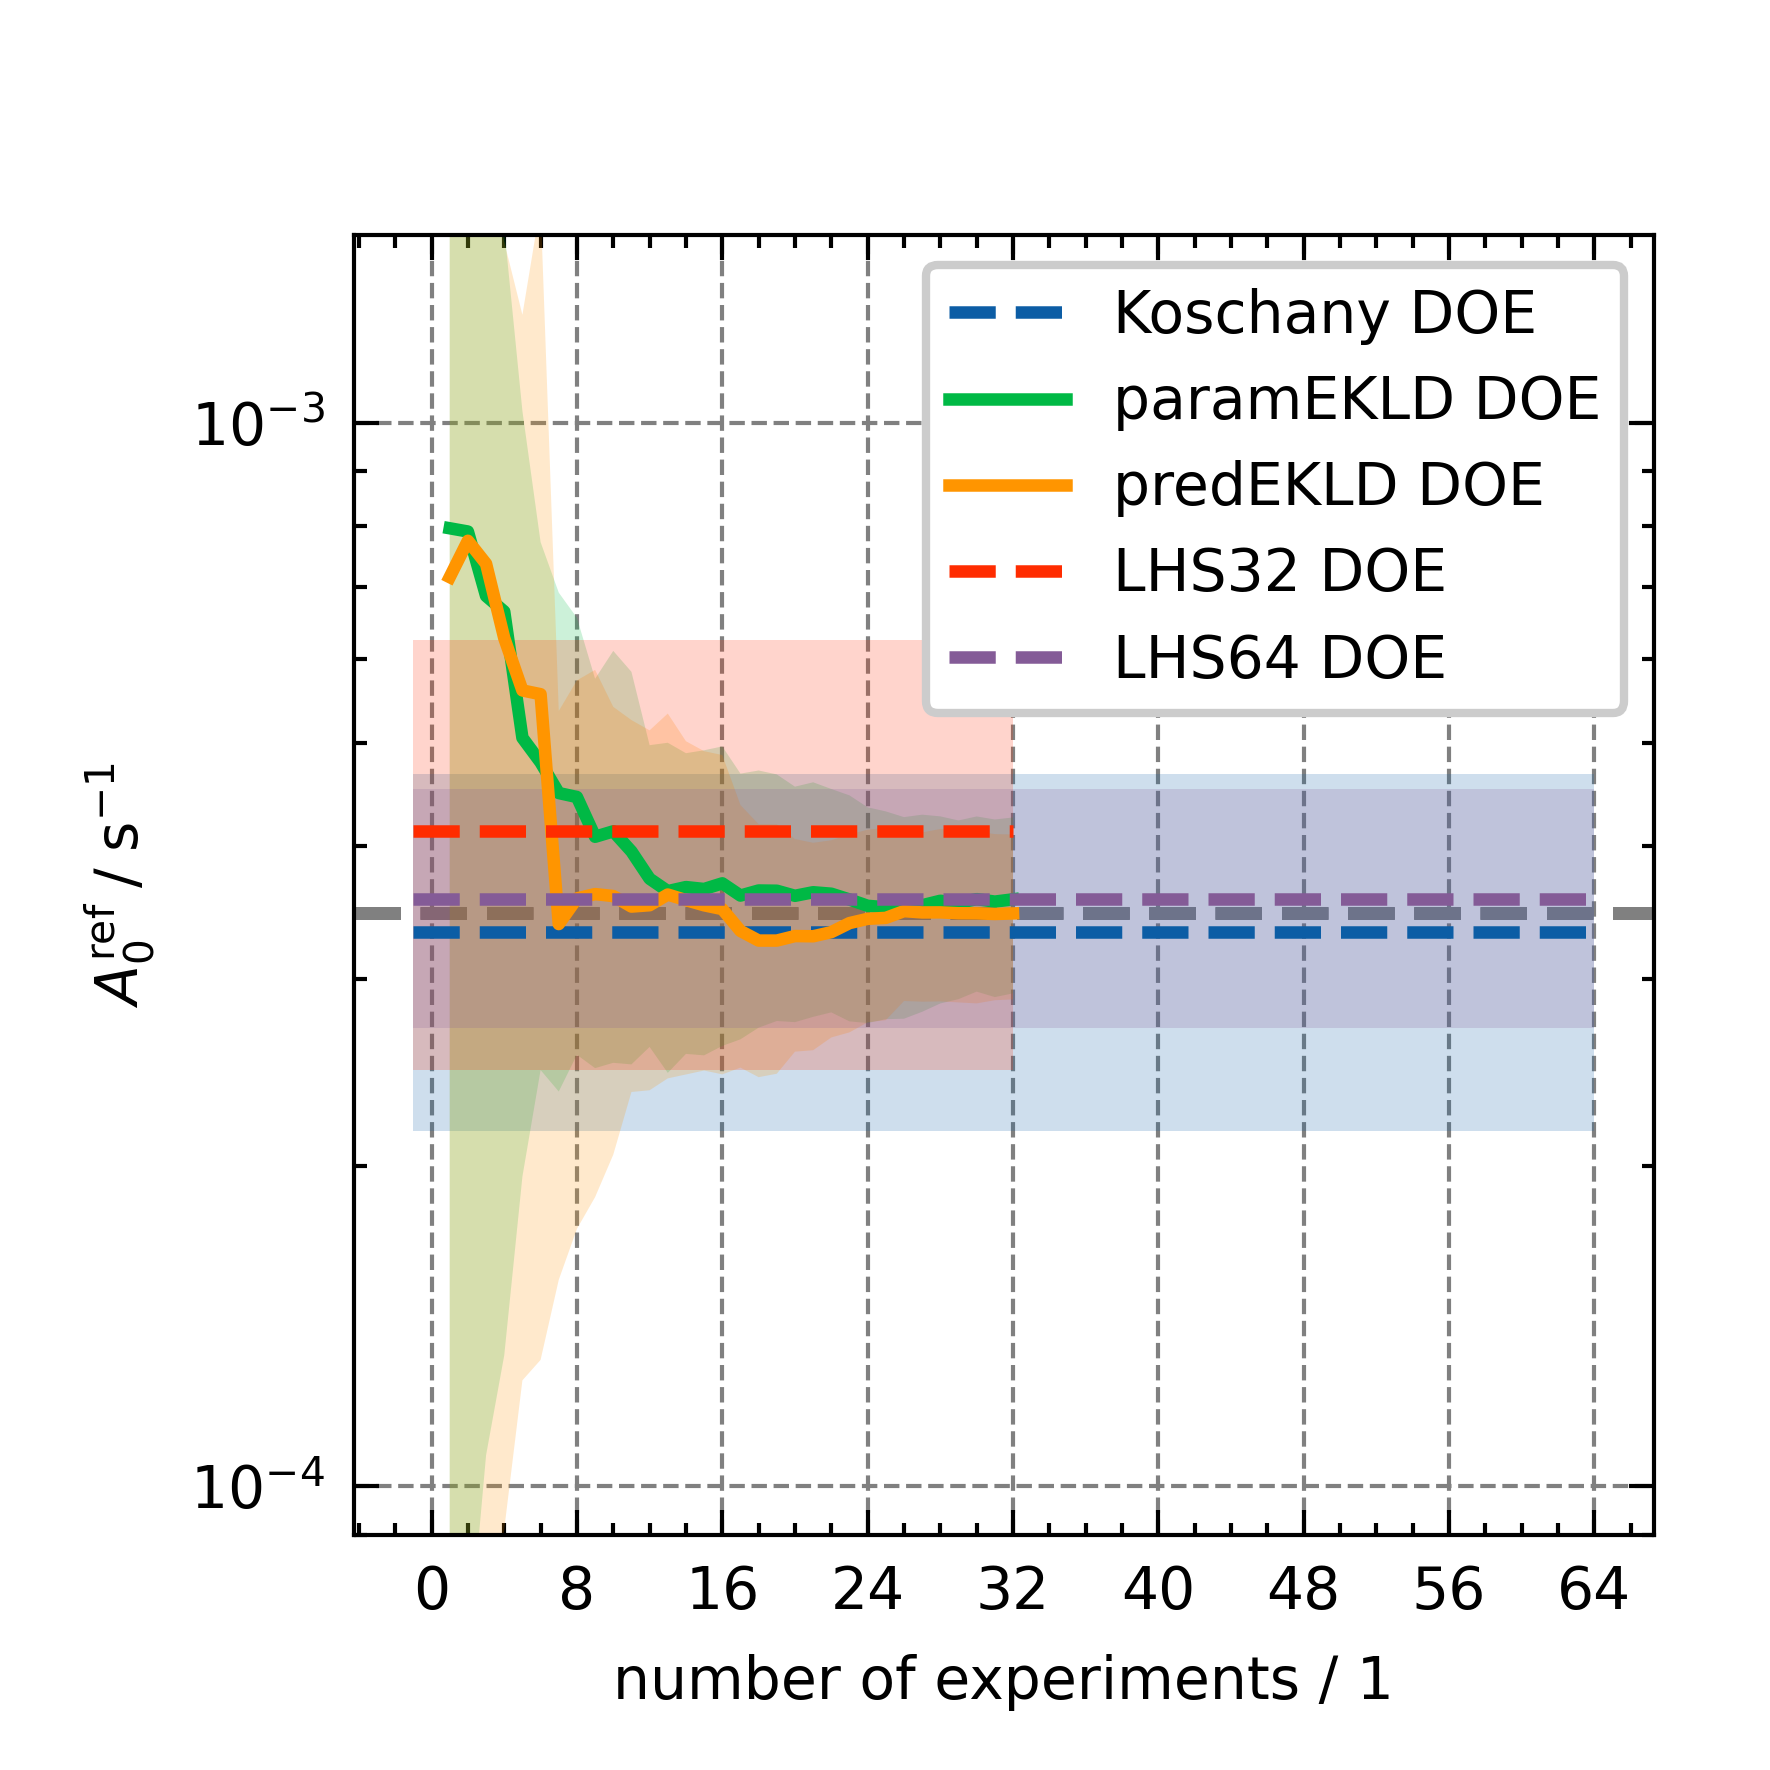

In [26]:
plot_parameter_evolution("k0")
ax = plt.gca()
ax.set_ylabel(r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$")
ax.set_ylim(9e-5, 1.5e-3)
plt.savefig("figures/rev/KinFit_k0_evolution.png")
plt.savefig("figures/rev/KinFit_k0_evolution.pdf")
plt.savefig("figures/rev/KinFit_k0_evolution.svg")

(60000.0, 90000.0)

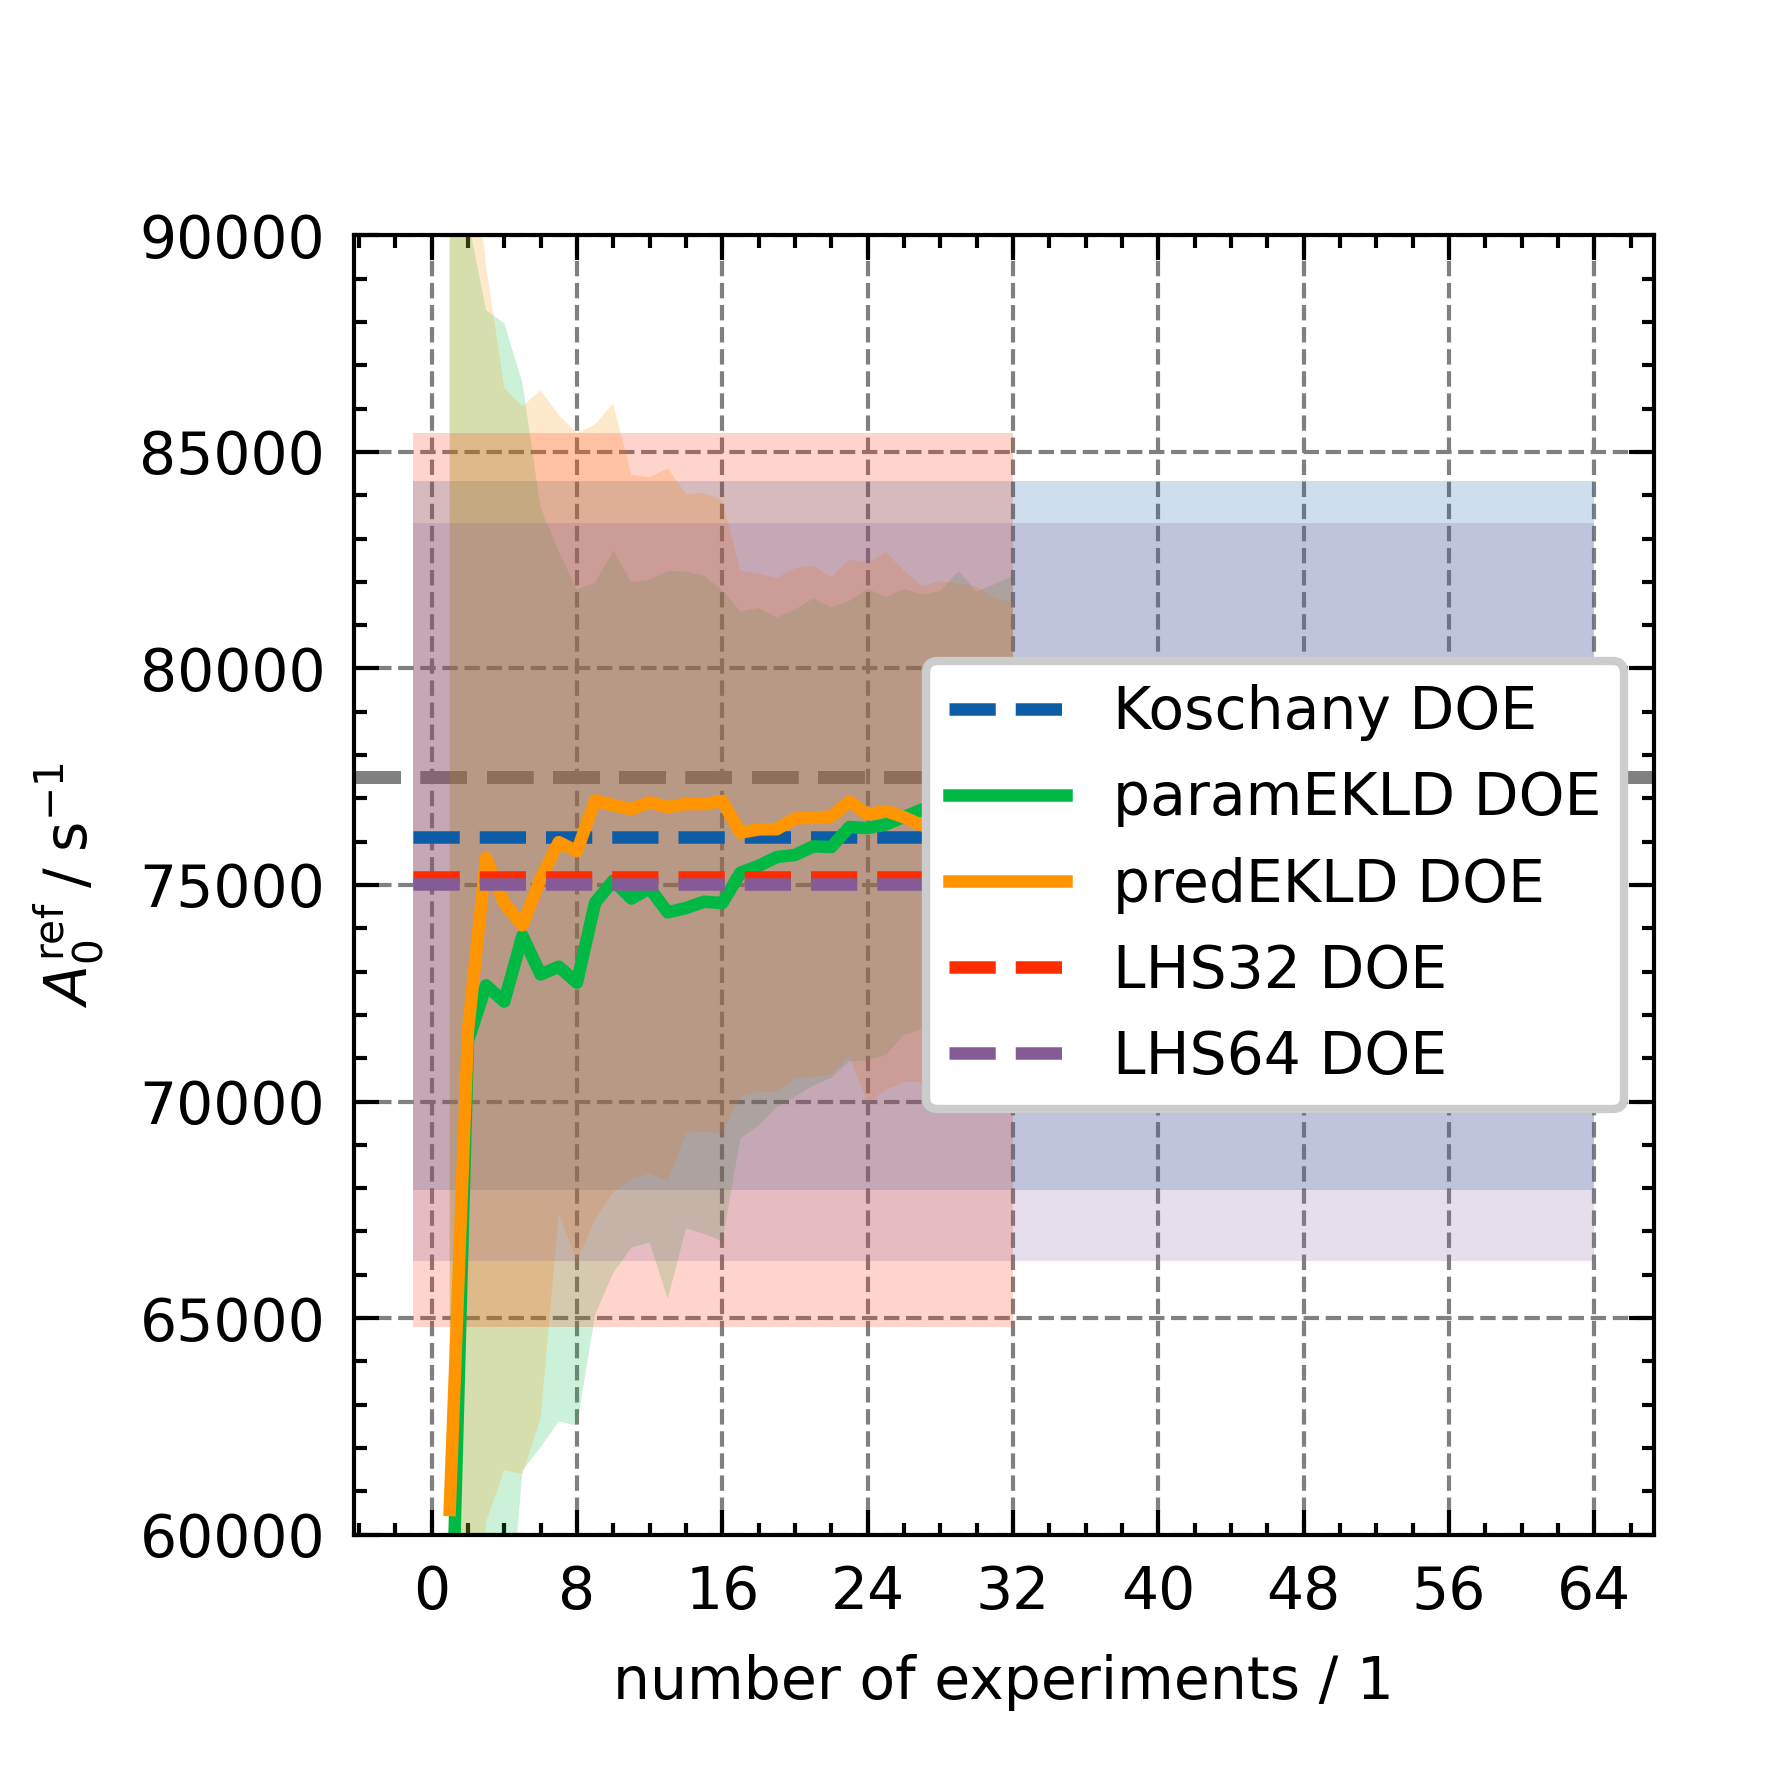

In [27]:
plot_parameter_evolution("Ea_k")
ax = plt.gca()
ax.set_yscale("linear")
ax.set_ylabel(r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$")
ax.set_ylim(60000, 90000)

## Parameter distributions

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning:

Unscientific behavior. No xlabel provided.

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning:

Unscientific behavior. No ylabel provided.



(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)


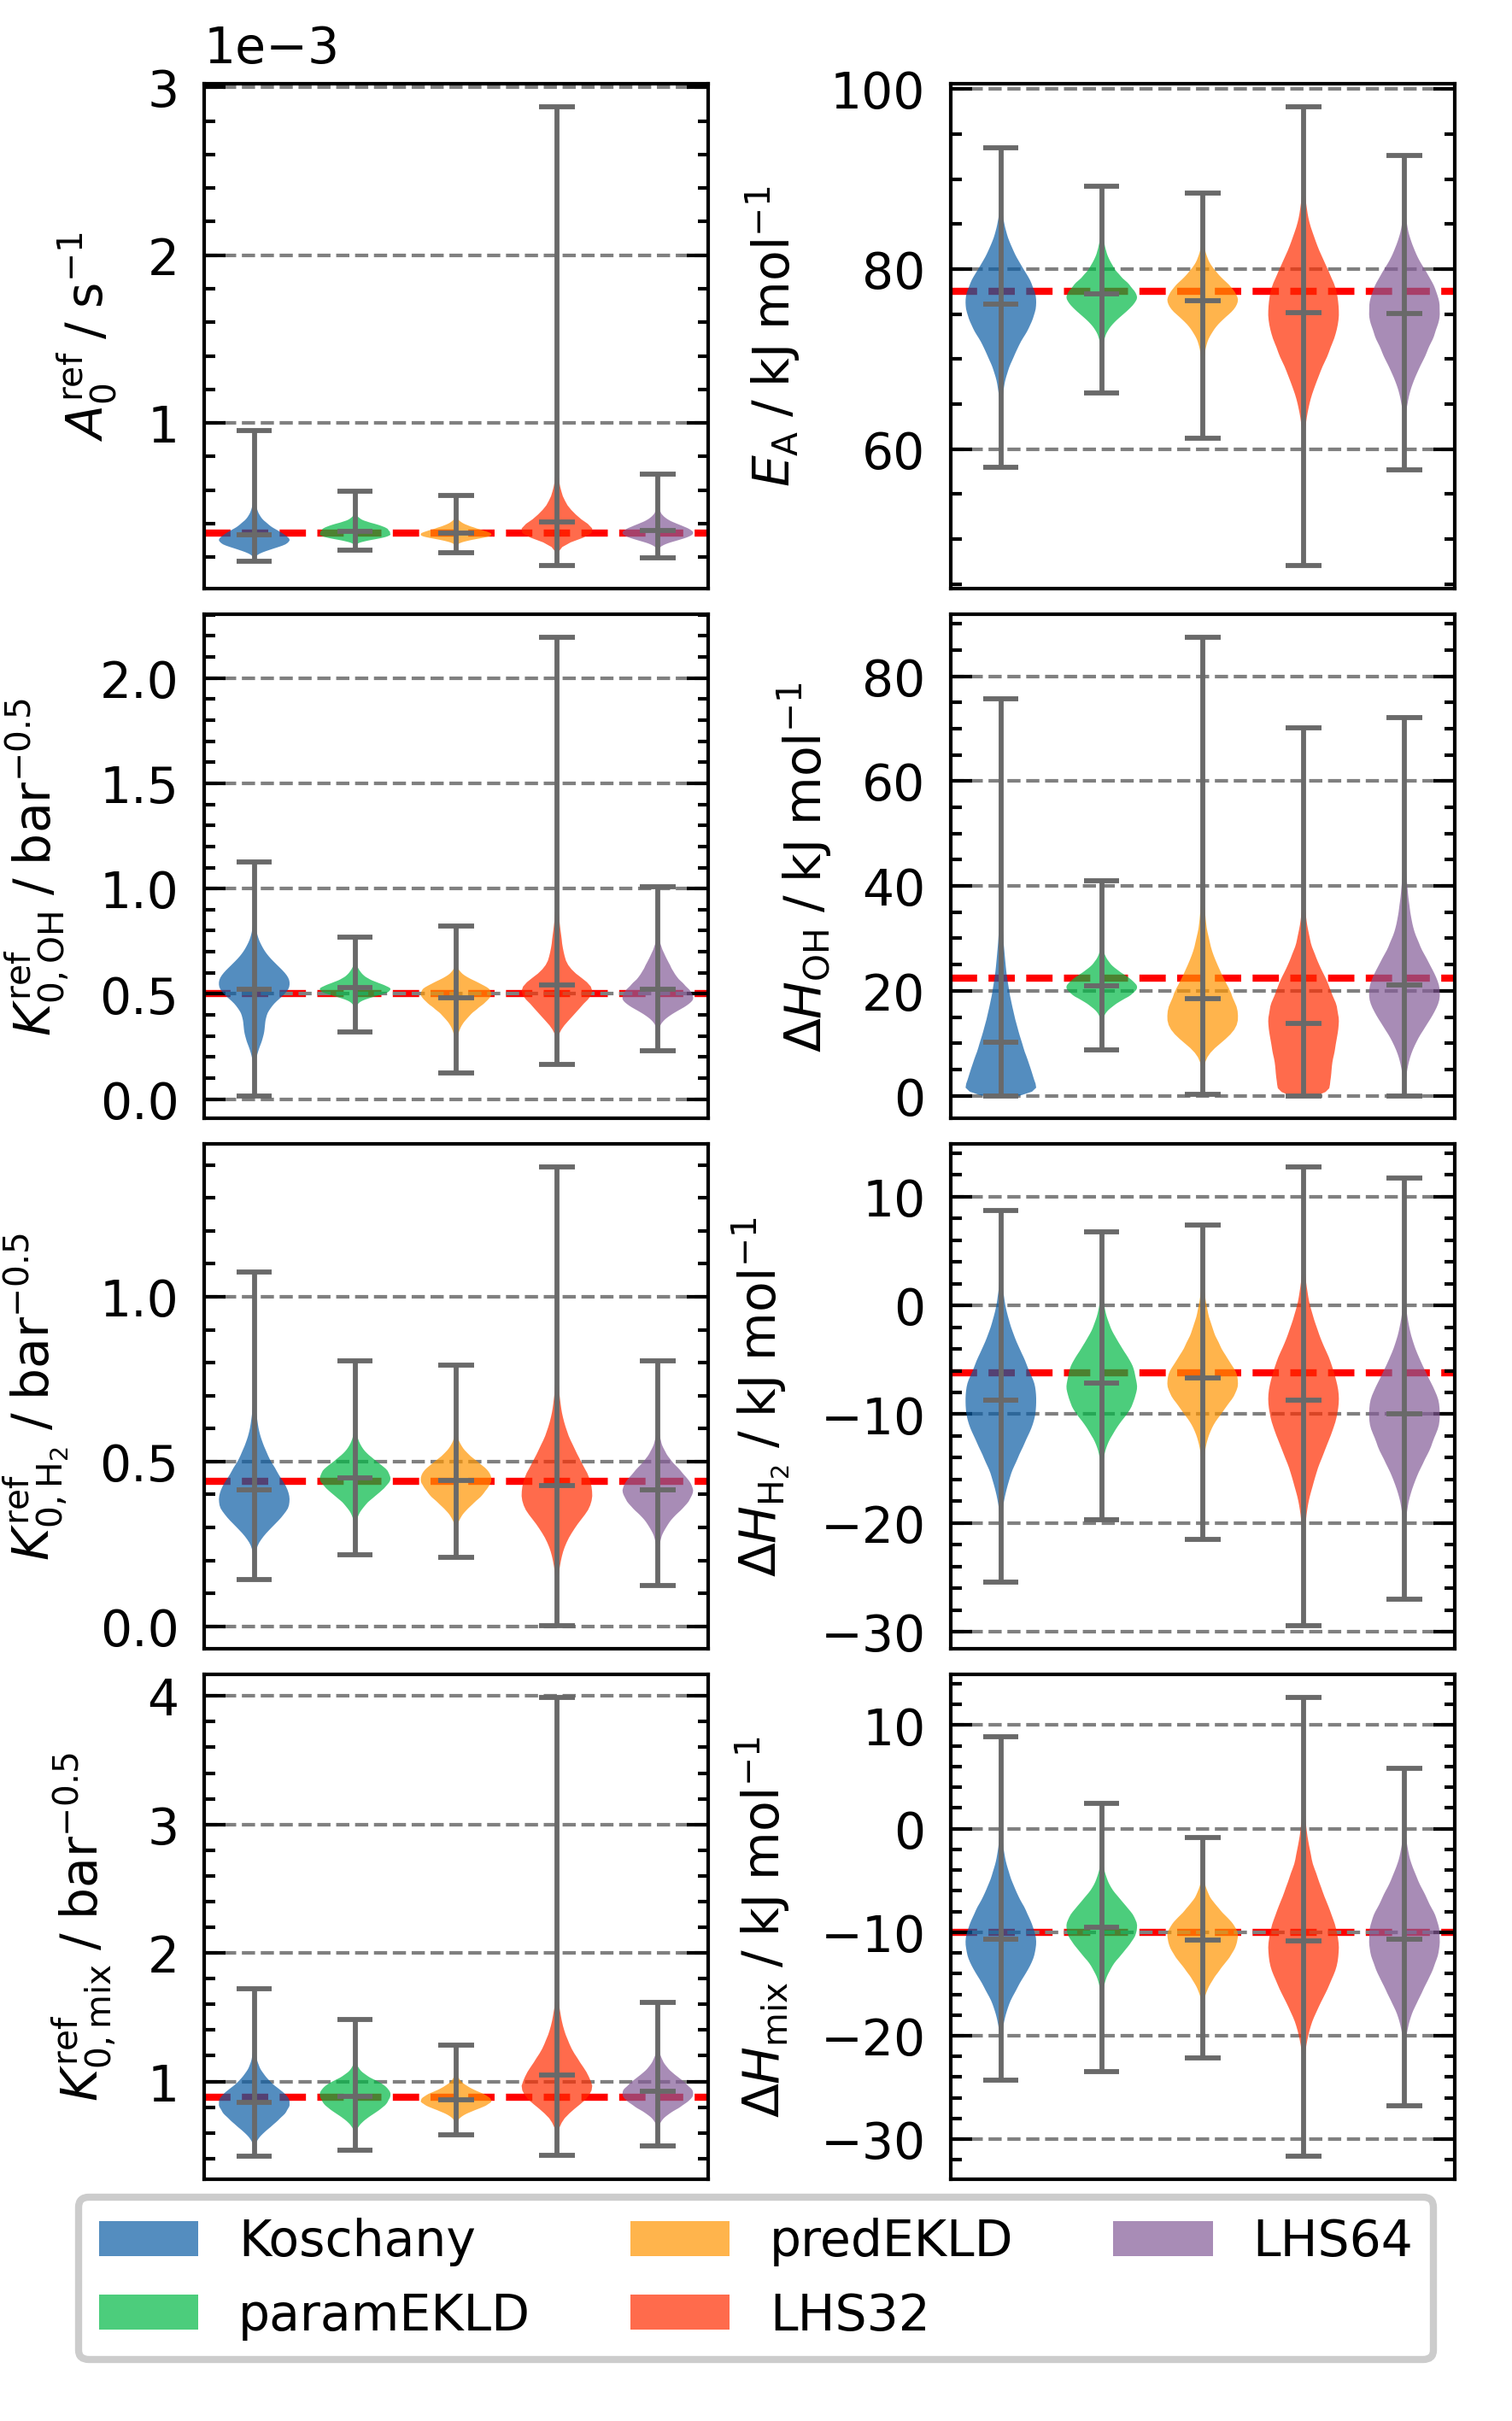

In [36]:
# fig, axes = plt.subplots(4, 2, figsize=(12, 16))
fig = ICIW_Plots.figure(layout="single_column", height=12 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.5 * ICIW_Plots.cm2inch,
    ax_layout=(4, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.2 * ICIW_Plots.cm2inch,
    # sharex=True,
    left_h=1.01 * ICIW_Plots.cm2inch,
    bottom_v=1.2 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()

param_names = ["k0", "Ea_k", "A_oh", "dH_oh", "A_h2", "dH_h2", "A_mix", "dH_mix"]

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}
labeldict = {
    "k0": r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$",
    "Ea_k": r"$E_\mathrm{A}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_oh": r"$K_{0,\mathrm{OH}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_oh": r"$\Delta H_\mathrm{OH}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_h2": r"$K_{0,\mathrm{H_2}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_h2": r"$\Delta H_\mathrm{H_2}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_mix": r"$K_{0,\mathrm{mix}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_mix": r"$\Delta H_\mathrm{mix}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
}

for idx, param in enumerate(param_names):
    ax = axes[idx]

    # Collect samples for each DOE method
    violin_data = []
    labels = []

    for i, ov_dict in enumerate(ov):
        samples = collect_param_samples_by_seed_and_step(ov_dict, param)
        samples = samples.isel(step=-1)
        samples = samples.stack(flat=("seed", "sample")).values
        print(samples.shape)
        if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
            samples = samples * 1e-3  # Convert to kJ/mol for better readability
        violin_data.append(samples)
        labels.append(ov_dict["DOE"])

    # Create violin plot
    parts = ax.violinplot(
        violin_data,
        positions=range(len(ov)),
        showmeans=True,
        # showmedians=True,
        widths=0.7,
    )

    # Make violin lines thinner
    for partname in ("cbars", "cmins", "cmaxes", "cmeans", "cmedians"):
        if partname in parts:

            parts[partname].set_color("dimgrey")
            parts[partname].set_linewidth(0.7)

    # Color the violins
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for i, pc in enumerate(parts["bodies"]):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
        # pc.set_linewidth(1.0)

    # Plot ground truth
    true_val = TRUE_PARAMS[keydict[param]]
    if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
        true_val = true_val * 1e-3  # Convert to kJ/mol for better readability
    ax.axhline(
        y=true_val,
        color="red",
        linestyle="--",
        linewidth=1.0,
        label="Ground Truth",
        zorder=0,
    )

    ax.set_ylabel(f"{labeldict[param]}")

    # Remove x-axis ticks and labels
    ax.set_xticks([])
    ax.set_xticklabels([])

    # Remove x-axis grid
    ax.grid(False, axis="x")

    # Adjust x-axis limits
    ax.set_xlim(-0.5, len(ov) - 0.5)

axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

# Create legend with DOE methods centered beneath the plots
from matplotlib.patches import Patch

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
legend_elements = [
    Patch(facecolor=colors[0], alpha=0.7, label="Koschany"),
    Patch(facecolor=colors[1], alpha=0.7, label="paramEKLD"),
    Patch(facecolor=colors[2], alpha=0.7, label="predEKLD"),
    Patch(facecolor=colors[3], alpha=0.7, label="LHS32"),
    Patch(facecolor=colors[4], alpha=0.7, label="LHS64"),
]
fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    frameon=True,
    bbox_to_anchor=(0.5, 0.015),
)

# plt.tight_layout()
plt.savefig("figures/rev/KinFit_parameter_comparison.png")
plt.savefig("figures/rev/KinFit_parameter_comparison.svg")
plt.savefig("figures/rev/KinFit_parameter_comparison.pdf")
plt.show()

In [28]:
import pandas as pd

pd.set_option("display.float_format", lambda x: "%.2e" % x)

var_names=[
    "k0",
    "Ea_k",
    "A_oh",
    "dH_oh",
    "A_h2",
    "dH_h2",
    "A_mix",
    "dH_mix"
]

for ov_dict in ov:
    print("=" * 40)
    print(f"Results for {ov_dict['ID']} - {ov_dict['DOE']}")
    print("-" * 40)
    
    ds = xarray.Dataset()

    for param in var_names:
        samples = collect_param_samples_by_seed_and_step(ov_dict, param)
        samples = samples.isel(step=-1)
        samples = samples.stack(flat=("seed", "sample")).values
        ds[param] = (("flat",), samples)
        print(samples.shape)
    # display(ds)
    sum=az.summary(ds, sample_dims=["flat"], var_names=var_names, round_to=14, fmt="wide", kind="stats",ci_kind="hdi", ci_prob=0.95)
    # display(az.summary(ds, var_names=var_names, round_to=14, fmt="wide"))

    # sum = (
    #     az.summary(
    #         ov_dict["idatas"][-1],
    #         var_names=[
    #             "k0",
    #             "Ea_k",
    #             "A_oh",
    #             "dH_oh",
    #             "A_h2",
    #             "dH_h2",
    #             "A_mix",
    #             "dH_mix",
    #         ],
    #         round_to=14,
    #         fmt="wide",
    #     ),
    # )
    sum.to_csv(f"data/summaries/rev/{ov_dict['ID']}_parameter_summary.csv")
    display(sum)

Results for H_001 - Koschany DOE
----------------------------------------
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)


,mean,sd,hdi95_lb,hdi95_ub
k0,3.32e-04,6.85e-05,2.31e-04,4.96e-04
Ea_k,7.61e+04,4.17e+03,6.78e+04,8.42e+04
A_oh,5.22e-01,1.31e-01,2.41e-01,7.58e-01
dH_oh,1.02e+04,8.59e+03,3.17e+02,3.18e+04
A_h2,4.15e-01,9.16e-02,2.67e-01,6.24e-01
dH_h2,-8.72e+03,4.23e+03,-1.68e+04,-2.73e+02
A_mix,8.39e-01,1.44e-01,5.85e-01,1.15e+00
dH_mix,-1.07e+04,3.74e+03,-1.77e+04,-2.97e+03


Results for H_002 - paramEKLD DOE
----------------------------------------
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)


,mean,sd,hdi95_lb,hdi95_ub
k0,3.56e-04,3.63e-05,2.95e-04,4.31e-04
Ea_k,7.72e+04,2.34e+03,7.29e+04,8.23e+04
A_oh,5.30e-01,3.94e-02,4.63e-01,6.20e-01
dH_oh,2.10e+04,2.69e+03,1.60e+04,2.67e+04
A_h2,4.51e-01,5.32e-02,3.48e-01,5.58e-01
dH_h2,-7.10e+03,3.00e+03,-1.27e+04,-1.07e+03
A_mix,8.82e-01,1.06e-01,6.77e-01,1.08e+00
dH_mix,-9.55e+03,2.44e+03,-1.43e+04,-4.73e+03


Results for H_003 - predEKLD DOE
----------------------------------------
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)


,mean,sd,hdi95_lb,hdi95_ub
k0,3.45e-04,3.20e-05,2.91e-04,4.15e-04
Ea_k,7.65e+04,2.49e+03,7.12e+04,8.13e+04
A_oh,4.79e-01,6.78e-02,3.30e-01,5.95e-01
dH_oh,1.84e+04,6.84e+03,8.36e+03,3.45e+04
A_h2,4.42e-01,5.53e-02,3.36e-01,5.50e-01
dH_h2,-6.65e+03,3.06e+03,-1.24e+04,-1.79e+02
A_mix,8.60e-01,7.21e-02,7.27e-01,1.01e+00
dH_mix,-1.07e+04,2.36e+03,-1.54e+04,-6.21e+03


Results for H_007 - LHS32 DOE
----------------------------------------
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)


,mean,sd,hdi95_lb,hdi95_ub
k0,4.13e-04,1.06e-04,2.71e-04,6.76e-04
Ea_k,7.52e+04,5.30e+03,6.48e+04,8.55e+04
A_oh,5.41e-01,1.30e-01,3.48e-01,8.72e-01
dH_oh,1.38e+04,8.26e+03,7.55e+02,3.11e+04
A_h2,4.27e-01,1.19e-01,2.09e-01,6.85e-01
dH_h2,-8.69e+03,4.72e+03,-1.80e+04,5.01e+02
A_mix,1.05e+00,2.24e-01,7.10e-01,1.57e+00
dH_mix,-1.09e+04,4.65e+03,-1.94e+04,-1.19e+03


Results for H_008 - LHS64 DOE
----------------------------------------
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)


,mean,sd,hdi95_lb,hdi95_ub
k0,3.57e-04,4.75e-05,2.76e-04,4.62e-04
Ea_k,7.50e+04,4.39e+03,6.63e+04,8.34e+04
A_oh,5.21e-01,8.74e-02,3.78e-01,7.15e-01
dH_oh,2.11e+04,7.97e+03,7.24e+03,3.96e+04
A_h2,4.13e-01,6.77e-02,2.82e-01,5.49e-01
dH_h2,-9.96e+03,3.97e+03,-1.76e+04,-2.03e+03
A_mix,9.26e-01,1.17e-01,7.18e-01,1.18e+00
dH_mix,-1.07e+04,3.95e+03,-1.82e+04,-2.91e+03
